## This Notebook cleans the data using a custom cleaner script and then tries to apply reduction and clustering using umap alogrithm and hierarchical clustering. At the end i implemented a simple approach to integrate in future use. The approach is that to cluster the data first and choose the best number of clusters using silhouette score. After that a pipeline is created to reduce and cluster to data and tune the reduction parameters of umap algorithm to find the model that fits the best silhouette score to the clustering in reduction mode. 

In [1]:
import pandas as pd
import seaborn as sn
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt


combined_files = pd.read_csv("data/cleaned data/combined_OESdata_1.csv")
ostbahnhof = pd.read_csv("data/cleaned data/Ostbahnhof_cleaned.csv")
messtage = pd.read_csv("data/cleaned data/KopieMesstage_cleaned.csv")

# Shape :

In [56]:
duplicates_all_columns0 = combined_files[combined_files.duplicated()]
duplicates_all_columns1 = ostbahnhof[ostbahnhof.duplicated()]
duplicates_all_columns2 = messtage[messtage.duplicated()]
## checking for duplicate rows 
print(duplicates_all_columns0.shape)
print(duplicates_all_columns1.shape)
print(duplicates_all_columns2.shape)

(0, 23)
(86, 22)
(390, 22)


# Checking for violations based on 
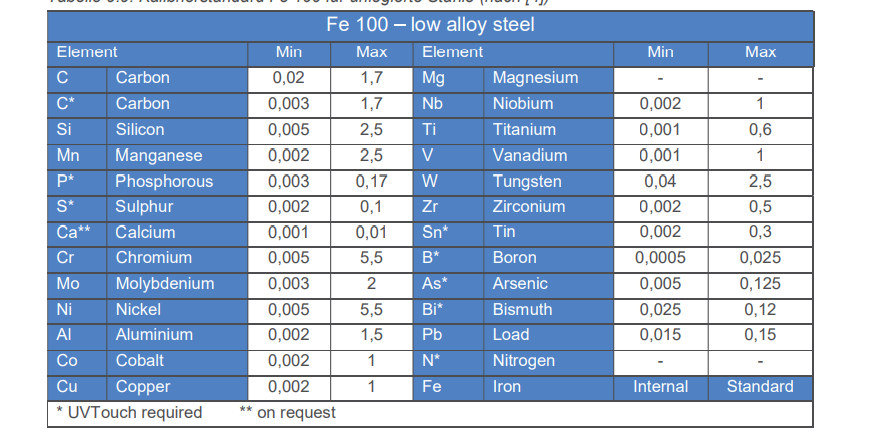


In [3]:
dic = {
    'Element' :  ['Fe', 'C', 'Si', 'Mn', 'P', 'S', 'Cr', 'Mo', 'Ni', 'Al', 'Co', 'Cu', 'Nb', 'Ti', 'V', 'W'
           , 'Pb', 'Sn', 'B', 'Ca', 'Zr', 'As', 'Bi'],
    
    'Max' : [100,1.7,2.5,2.5,0.17,0.1,5.5,2,5.5,1.5,1,1,1,0.6,1,2.5,0.15,0.3,0.025,0.01,0.5,0.125,0.12],
    'Min' : [0,0.02,0.005,0.002,0.003,0.002,0.005,0.003,0.005,0.002,0.002,0.002,0.002,0.001,0.001,0.04,0.015,0.002,0.0005
       ,0.001,0.002,0.005,0.025]}

checking_df = pd.DataFrame(dic)
checking_df.set_index('Element', inplace=True)
## checking
description1 = combined_files.describe()
min_vec1 = description1.loc['min']
max_vec1 = description1.loc['max']


rows_to_exclude_ostbahnhof = set(checking_df.index) - set(ostbahnhof.columns)
checking_df_ostbahnhof = checking_df[~checking_df.index.isin(rows_to_exclude_ostbahnhof)]
description2 = ostbahnhof.describe()
min_vec2 = description2.loc['min']
max_vec2 = description2.loc['max']


rows_to_exclude_messtage = set(checking_df.index) - set(messtage.columns)
checking_df_messtage = checking_df[~checking_df.index.isin(rows_to_exclude_messtage)]
description3 = messtage.describe()
min_vec3 = description3.loc['min']
max_vec3 = description3.loc['max']



In [4]:
print('Checking combined files : ')
print("checking for minimum :",(min_vec1.reset_index(drop=True) >= checking_df['Min'].reset_index(drop=True)).sum()," and length is ",len(combined_files.columns))
print("checking for maximum :",(max_vec1.reset_index(drop=True) <= checking_df['Max'].reset_index(drop=True)).sum()," and length is",len(combined_files.columns))

Checking combined files : 
checking for minimum : 20  and length is  23
checking for maximum : 22  and length is 23


In [5]:
print('Checking ostbahnhof file : ')
print("checking for minimum :",(min_vec2.reset_index(drop=True) >= checking_df_ostbahnhof['Min'].reset_index(drop=True)).sum()," and length is",len(ostbahnhof.columns))
print("checking for maximum :",(max_vec2.reset_index(drop=True) <= checking_df_ostbahnhof['Max'].reset_index(drop=True)).sum()," and length is",len(ostbahnhof.columns))

Checking ostbahnhof file : 
checking for minimum : 1  and length is 22
checking for maximum : 1  and length is 22


In [6]:

print('Checking messtage file : ')
print("checking for minimum :",(min_vec3.reset_index(drop=True) >= checking_df_messtage['Min'].reset_index(drop=True)).sum()," and length is",len(messtage.columns))
print("checking for maximum :",(max_vec3.reset_index(drop=True) <= checking_df_messtage['Max'].reset_index(drop=True)).sum()," and length is",len(messtage.columns))

Checking messtage file : 
checking for minimum : 20  and length is 22
checking for maximum : 22  and length is 22


## Need to filter data 

1. in combined files we have 2 violations in minimum and 1 violation in maximum
2. in ostbahnhof we have 21 violation in minimum and 22 in maximum 
3. in messtage we have 2 violations in minimum and no violations in maximum


In [7]:
df1 = combined_files
for i, col in enumerate(df1.columns):
    min_value = checking_df['Min'].reset_index(drop=True)[i]
    max_value = checking_df['Max'].reset_index(drop=True)[i]
    df1 = df1[df1[col] >= min_value]
    df1 = df1[df1[col] <= max_value ]
    
df2 = ostbahnhof
for i, col in enumerate(df2.columns):
    min_value = checking_df_ostbahnhof['Min'].reset_index(drop=True)[i]
    max_value = checking_df['Max'].reset_index(drop=True)[i]
    df2 = df2[df2[col] >= min_value]
    df2 = df2[df2[col] <= max_value ]
    
df3 = messtage
for i, col in enumerate(df3.columns):
    min_value = checking_df_messtage['Min'].reset_index(drop=True)[i]
    max_value = checking_df['Max'].reset_index(drop=True)[i]
    df3 = df3[df3[col] >= min_value]
    df3 = df3[df3[col] <= max_value ]



### Filtered datasets : df1,df2,df3

# Datasets analysis : combined datasets

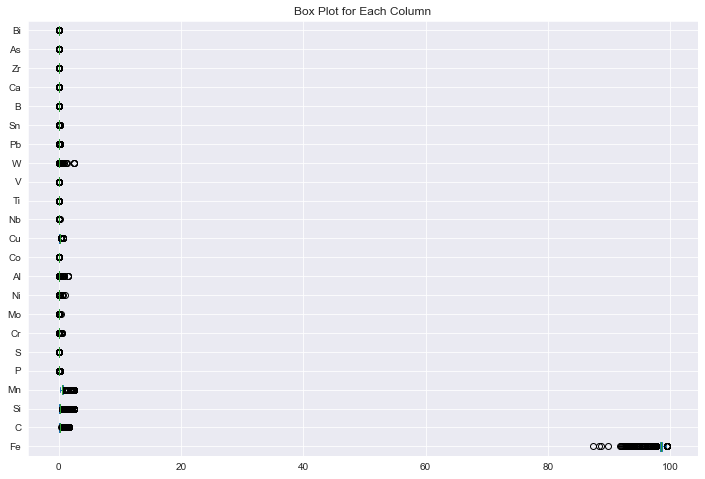

In [8]:
# Box plot for each column
combined_files.plot.box(figsize=(12, 8), vert=False)
plt.title('Box Plot for Each Column')
plt.show()


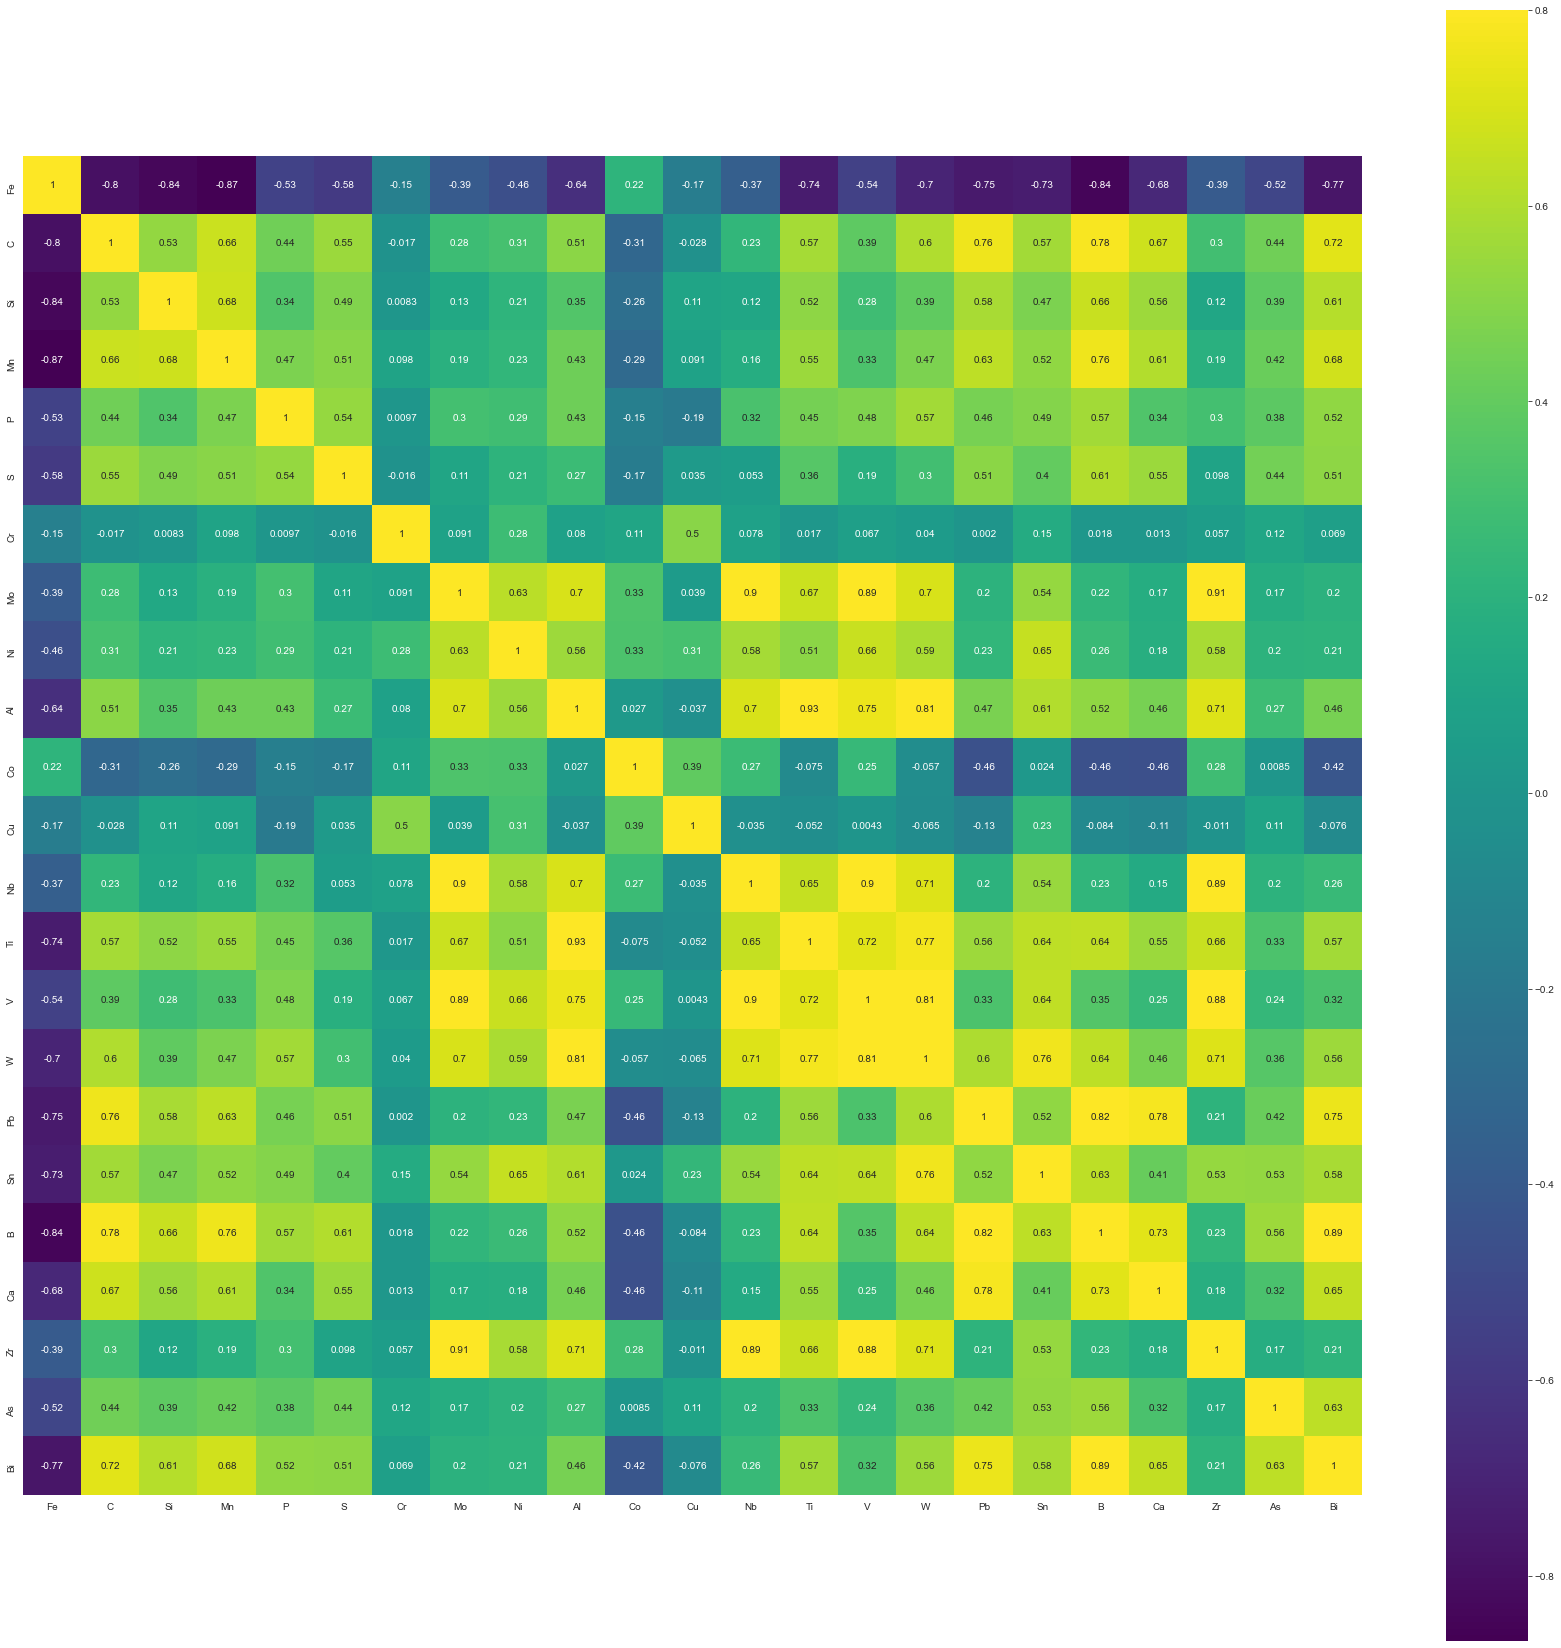

In [9]:
figure(figsize=(30,30))
sn.heatmap(combined_files.select_dtypes('number').corr(),vmax=.8, annot=True,square=True,cmap='viridis');

## we see some highly correlated columns like 'Al' and 'W'

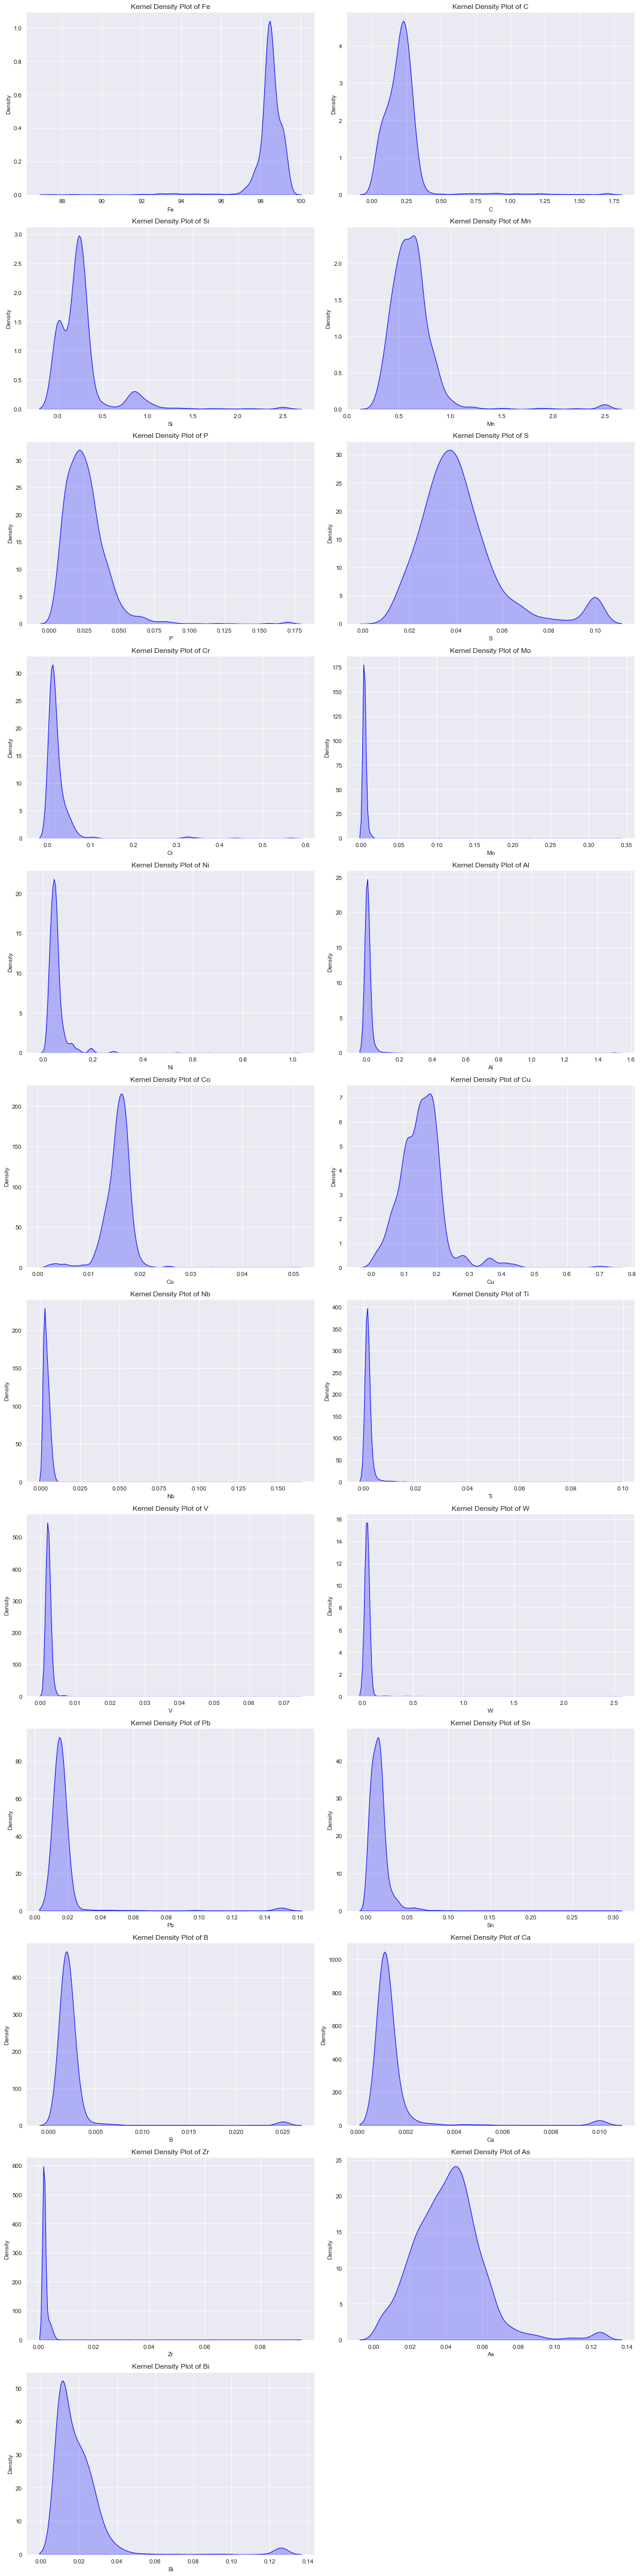

In [10]:
columns = combined_files.columns
num_columns = len(columns)
num_rows = (num_columns // 2) + (num_columns % 2)
num_cols = 2
plt.figure(figsize=(15, 5 * num_rows))
for i, column in enumerate(columns, 1):
    plt.subplot(num_rows, num_cols, i)
    sn.kdeplot(combined_files[column], shade=True,color='b')
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(f'Kernel Density Plot of {column}')
plt.tight_layout()
plt.show()

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
ct = ColumnTransformer([
        ('somename', StandardScaler(), combined_files.columns)
    ], remainder='passthrough')
## scale only continuous columns
scaled_df = ct.fit_transform(combined_files)
scaled_features_df = pd.DataFrame(scaled_df, index=combined_files.index, columns=combined_files.columns)
scaled_features_df.describe()

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,...,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03,2.598000e+03
mean,-1.726307e-14,-1.750375e-16,-4.375937e-17,6.563905e-17,-1.148683e-16,6.563905e-17,-9.298866e-17,4.375937e-17,-1.531578e-16,3.281953e-17,...,-2.187968e-17,4.922929e-17,-3.281953e-17,8.751874e-17,-2.187968e-16,-6.563905e-17,-9.845858e-17,-3.692197e-17,-1.093984e-17,-1.340131e-16
std,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,...,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00,1.000193e+00
min,-1.249038e+01,-1.180321e+00,-8.075517e-01,-1.365246e+00,-1.425234e+00,-1.758012e+00,-4.163974e-01,-1.704948e-01,-1.020308e+00,-1.285474e-01,...,-2.547139e-01,-6.509635e-01,-9.254691e-02,-1.847115e-01,-8.896103e-01,-4.666164e-01,-3.244189e-01,-1.848185e-01,-1.950500e+00,-5.770801e-01
25%,-1.097366e-01,-4.688376e-01,-5.070657e-01,-4.968624e-01,-6.396085e-01,-6.131712e-01,-3.632665e-01,-1.704948e-01,-4.398625e-01,-1.285474e-01,...,-2.042951e-01,-2.611618e-01,-9.254691e-02,-1.847115e-01,-4.989667e-01,-2.781710e-01,-3.244189e-01,-1.848185e-01,-6.635196e-01,-5.770801e-01
50%,1.174312e-01,-4.407161e-02,-1.276641e-01,-1.208212e-01,-1.595043e-01,-1.615875e-01,-2.317043e-01,-1.226114e-01,-1.643345e-01,-1.214334e-01,...,-1.286669e-01,-6.626102e-02,-9.254691e-02,-1.847115e-01,-1.147271e-01,-1.839483e-01,-2.567372e-01,-1.848185e-01,8.862132e-03,-2.162432e-01
75%,3.445990e-01,2.214071e-01,2.106131e-02,2.629734e-01,3.891862e-01,3.397118e-01,4.154021e-02,3.300970e-02,8.180384e-02,-9.155463e-02,...,-5.303872e-02,1.286398e-01,-9.254691e-02,-1.847115e-01,1.862606e-01,-5.831799e-02,-1.213738e-01,-1.848185e-01,5.289073e-01,2.013382e-01
max,1.253270e+00,8.763924e+00,6.765304e+00,7.241057e+00,8.987416e+00,3.230124e+00,1.377714e+01,3.993187e+01,2.345882e+01,2.118495e+01,...,2.392110e+01,3.482098e+01,2.116257e+01,6.684826e+00,1.819429e+01,7.071201e+00,5.766936e+00,3.621017e+01,4.405608e+00,6.174062e+00


In [12]:
from sklearn.decomposition import PCA
import numpy as np
pca_df = PCA(0.95) ## specify explained variance needed
principalComponents_df = pca_df.fit_transform(scaled_df)
print('Explained variation per principal component: {}'.format(pca_df.explained_variance_ratio_))

Explained variation per principal component: [0.46437381 0.18013126 0.08335151 0.04408928 0.03536259 0.03034191
 0.0256753  0.02320644 0.01765766 0.01666993 0.01363006 0.01196129
 0.0109696 ]


In [13]:
print("columns in the dataframe : {}".format(len(combined_files.columns)))
print("components needed to represent 95% of the data :{}".format(len(pca_df.explained_variance_ratio_)))

columns in the dataframe : 23
components needed to represent 95% of the data :13


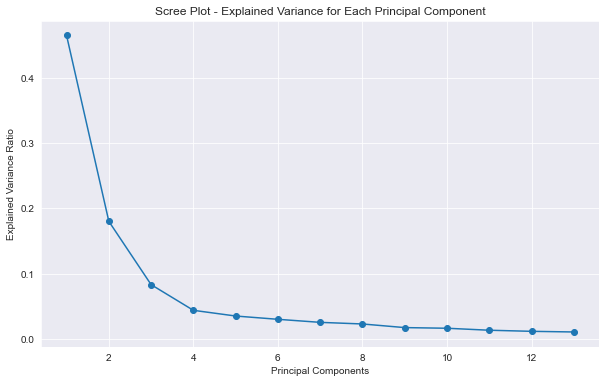

In [14]:
# Scree plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca_df.explained_variance_ratio_) + 1), pca_df.explained_variance_ratio_, marker='o')
plt.title('Scree Plot - Explained Variance for Each Principal Component')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.show()

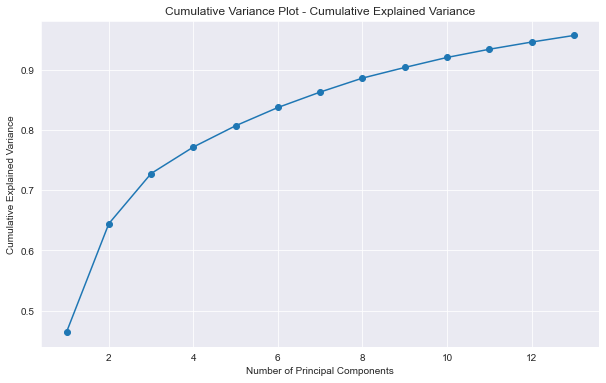

In [15]:
# Cumulative variance plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca_df.explained_variance_ratio_) + 1), pca_df.explained_variance_ratio_.cumsum(), marker='o')
plt.title('Cumulative Variance Plot - Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

### PCA is not really working here to get more than 80%. Trying UMAP

In [16]:
ct = ColumnTransformer([
        ('somename', StandardScaler(), df1.columns)
    ], remainder='passthrough')
## scale only continuous columns
scaled_df = ct.fit_transform(df1)
scaled_features_df = pd.DataFrame(scaled_df, index=df1.index, columns=df1.columns)
scaled_features_df.describe()

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,4.850000e+02,4.850000e+02,485.000000,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,...,485.000000,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,4.850000e+02,485.000000
mean,4.303545e-15,-8.790219e-17,0.000000,-4.065476e-16,-1.025526e-16,5.860146e-17,-5.860146e-17,-2.197555e-17,-2.930073e-17,-7.325183e-18,...,0.000000,3.516088e-16,-1.758044e-16,-1.758044e-16,-1.465037e-16,-1.318533e-16,1.025526e-16,-2.856821e-16,-6.958924e-17,0.000000
std,1.001033e+00,1.001033e+00,1.001033,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,...,1.001033,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033e+00,1.001033
min,-6.001737e+00,-1.078246e+00,-0.937467,-1.512234e+00,-1.851909e+00,-1.677037e+00,-4.147731e-01,-8.909526e-01,-1.602031e+00,-2.686114e-01,...,-0.511006,-2.048033e+00,-1.036815e-01,-2.408019e-01,-1.692534e+00,-8.132214e-01,-3.584804e-01,-5.072995e-01,-2.379145e+00,-0.645891
25%,-1.307357e-01,-4.791261e-01,-0.480635,-5.214671e-01,-6.811038e-01,-6.156537e-01,-3.269723e-01,-8.909526e-01,-6.352402e-01,-2.686114e-01,...,-0.313683,-6.028183e-01,-1.036815e-01,-2.408019e-01,-6.307523e-01,-3.185758e-01,-3.584804e-01,-5.072995e-01,-7.004046e-01,-0.482613
50%,1.628144e-01,-8.510993e-02,-0.171791,-4.967322e-02,-7.966301e-02,-1.890193e-01,-2.573943e-01,-2.707258e-01,-1.810734e-01,-2.334100e-01,...,-0.215021,-2.473254e-02,-1.036815e-01,-2.408019e-01,-8.880109e-02,-2.286403e-01,-2.993634e-01,-5.072995e-01,-5.196436e-02,-0.273981
75%,4.563644e-01,1.793667e-01,0.011585,2.848715e-01,5.378162e-01,3.260637e-01,-6.522640e-02,4.735463e-01,2.461133e-01,-1.383665e-01,...,-0.067029,4.088318e-01,-1.036815e-01,-2.408019e-01,3.646683e-01,-3.801400e-03,-1.220125e-01,-1.462720e-01,6.036808e-01,0.097929
max,1.337015e+00,7.924752e+00,7.089261,7.923643e+00,4.483268e+00,2.745393e+00,5.267432e+00,4.815134e+00,4.090793e+00,1.592399e+01,...,13.597588,1.269316e+01,1.915543e+01,5.578814e+00,5.220108e+00,9.934078e+00,4.962046e+00,4.095802e+00,5.085124e+00,7.971532


In [17]:
import seaborn as sns

sns.set(style='white', context='poster', rc={'figure.figsize':(14,10)})
import matplotlib.pyplot as plt
import seaborn as sns
import umap

def draw_umap(n_neighbors=10, min_dist=0.1, n_components=2, metric='euclidean', title='',data=scaled_features_df):
    fit = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        n_components=n_components,
        metric=metric
    )
    u = fit.fit_transform(data)
    fig = plt.figure()
    if n_components == 1:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], range(len(u)))
    if n_components == 2:
        ax = fig.add_subplot(111)
        ax.scatter(u[:,0], u[:,1],color='red',s=100)
    if n_components == 3:
        ax = fig.add_subplot(111, projection='3d')
        ax.scatter(u[:,0], u[:,1], u[:,2])
    plt.title(title, fontsize=18)



In [18]:
print(scaled_features_df.shape)

(485, 23)


<Figure size 576x288 with 0 Axes>

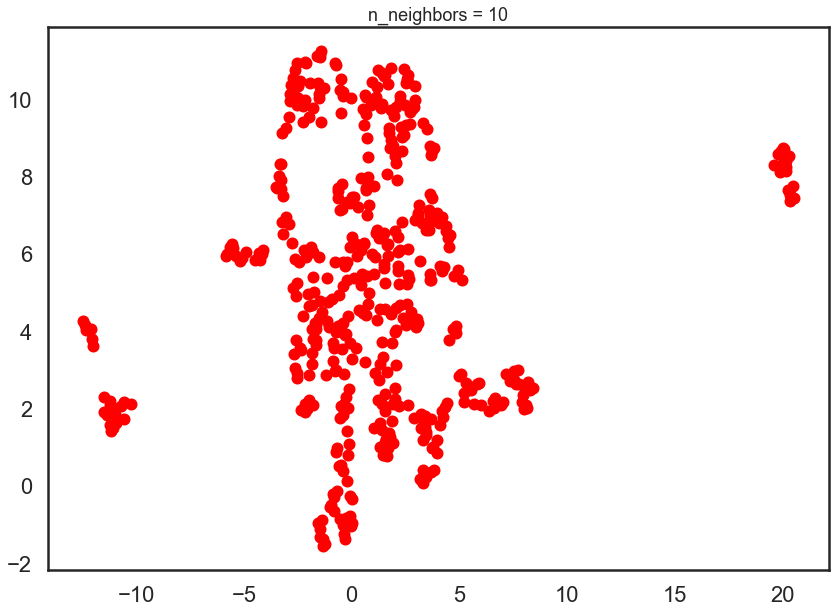

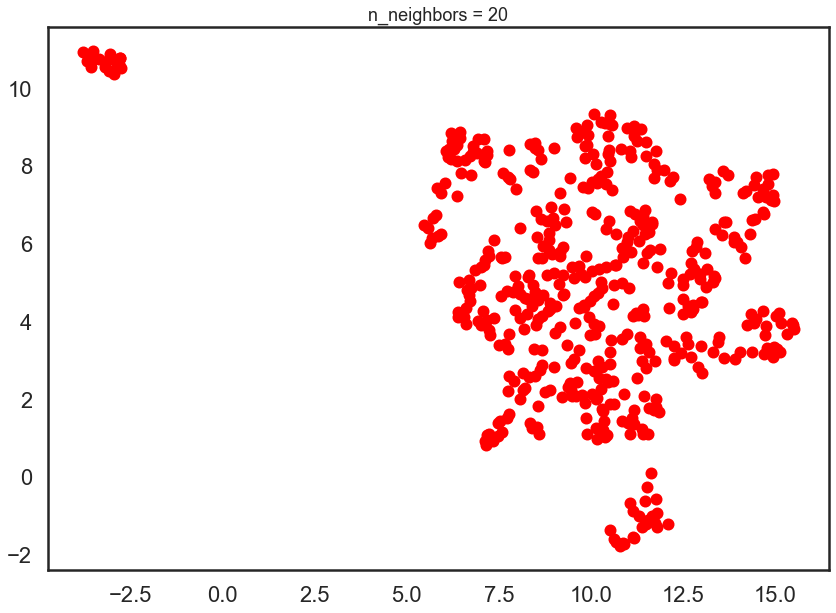

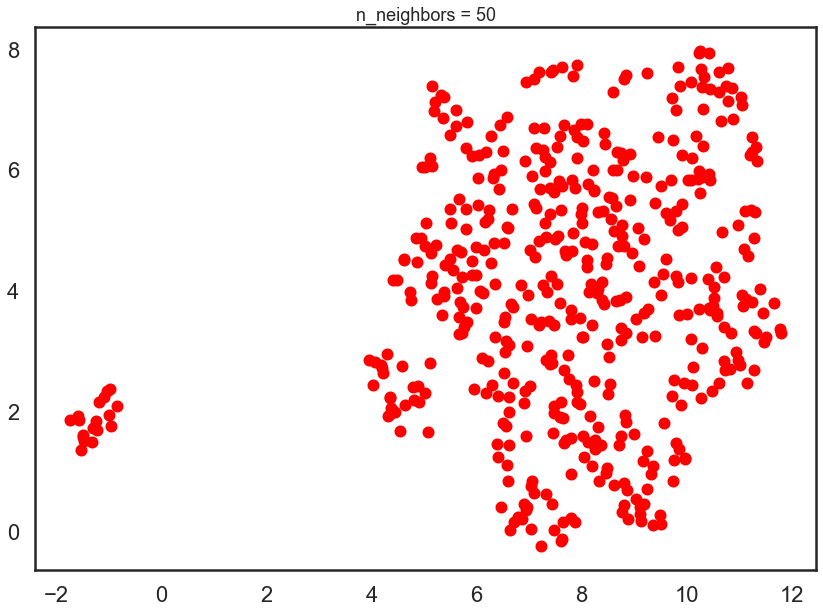

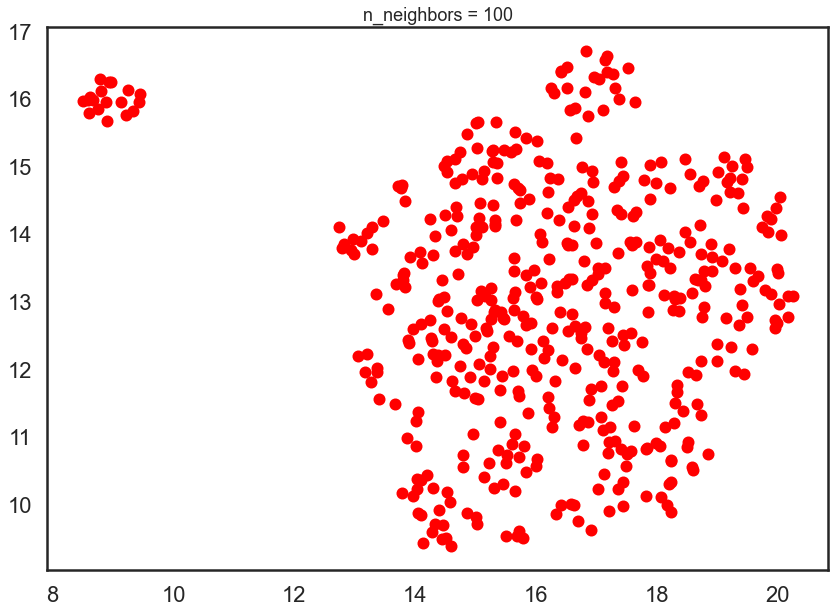

In [19]:
plt.figure(figsize=(8, 4))
for n in (10, 20, 50, 100):
    draw_umap(n_neighbors=n, min_dist=0.5,metric='euclidean',title='n_neighbors = {}'.format(n),data=scaled_features_df)

## We can see the clusters appearing in the reduced dataset (2 clusters)

In [20]:
ct = ColumnTransformer([
        ('somename', StandardScaler(), df2.columns)
    ], remainder='passthrough')
scaled_df_ostbahnhof = ct.fit_transform(df2)
scaled_features_df_ostbahnhof = pd.DataFrame(scaled_df_ostbahnhof, index=df2.index, columns=df2.columns)
print(df2.shape)

(61, 22)


<Figure size 576x288 with 0 Axes>

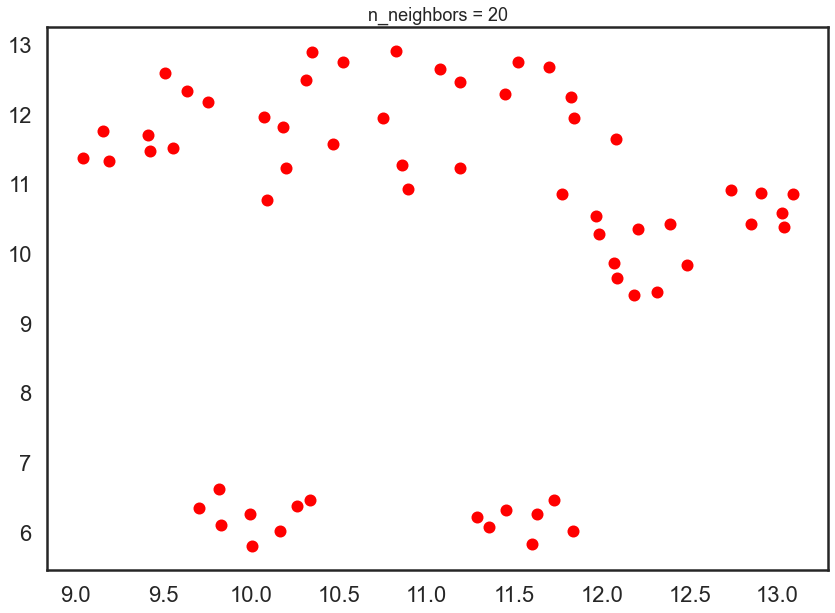

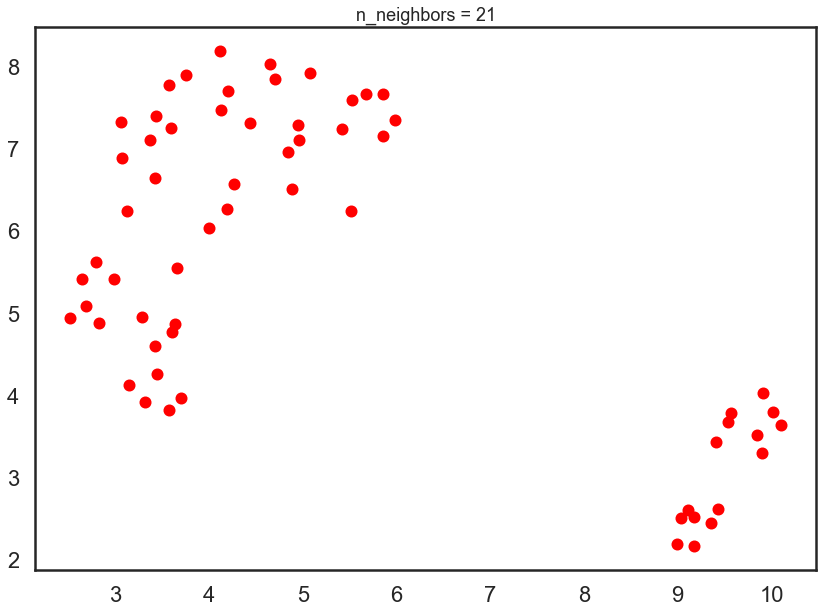

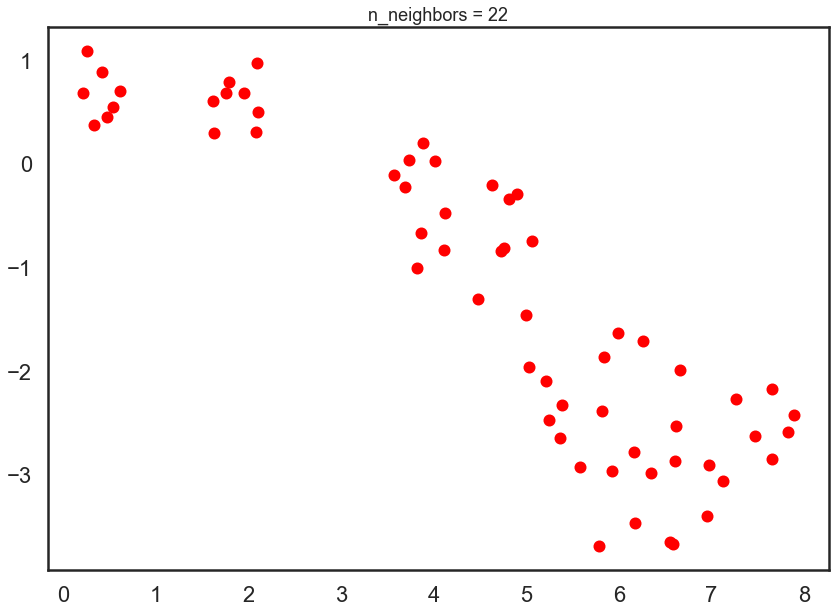

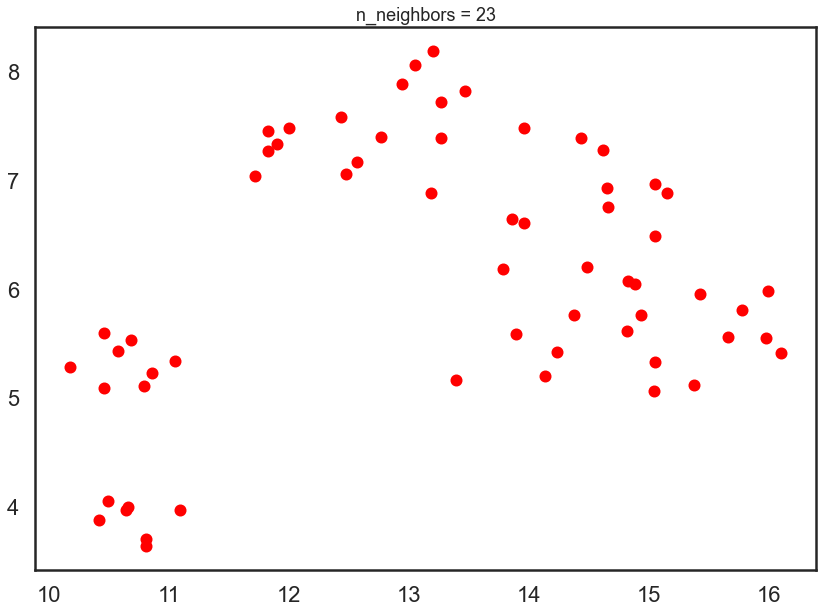

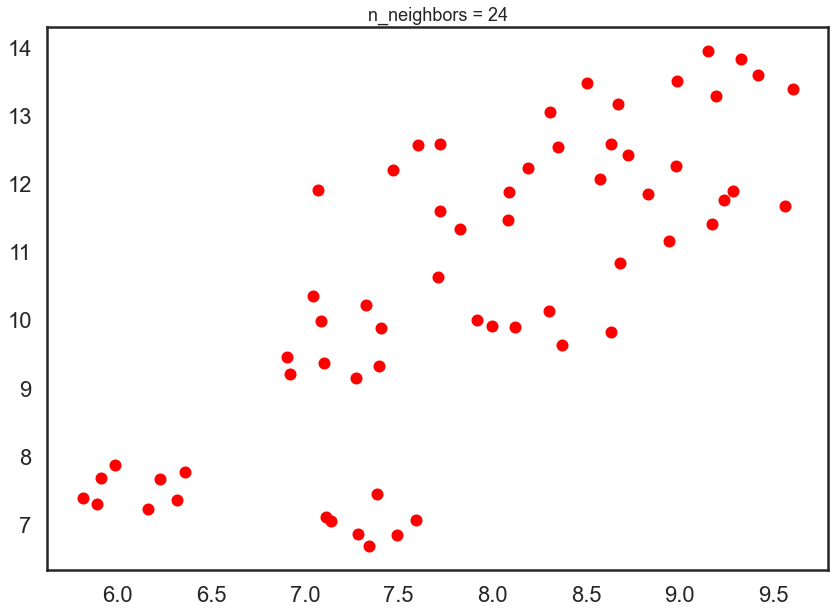

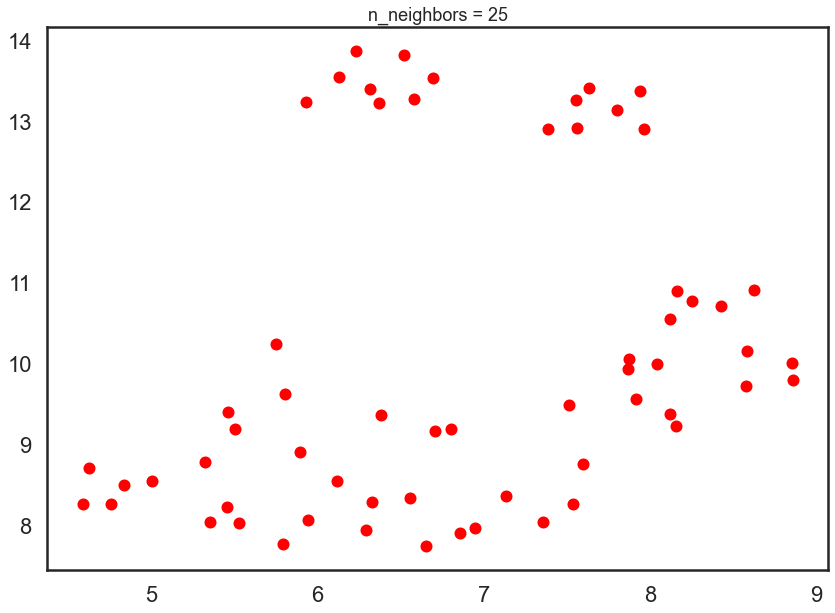

In [21]:
plt.figure(figsize=(8, 4))
for n in (20,21,22,23,24,25):
    draw_umap(n_neighbors=n, min_dist=0.1,metric='euclidean',title='n_neighbors = {}'.format(n),data=scaled_features_df_ostbahnhof)

## We can see the clusters appearing in the reduced dataset (3 clusters)

In [22]:
ct = ColumnTransformer([
    ('somename', StandardScaler(), df3.columns)
], remainder='passthrough')
scaled_df_messtage = ct.fit_transform(df3)
scaled_features_df_messtage = pd.DataFrame(scaled_df_messtage, index=df3.index, columns=df3.columns)
print(df3.shape)

(76, 22)


<Figure size 576x288 with 0 Axes>

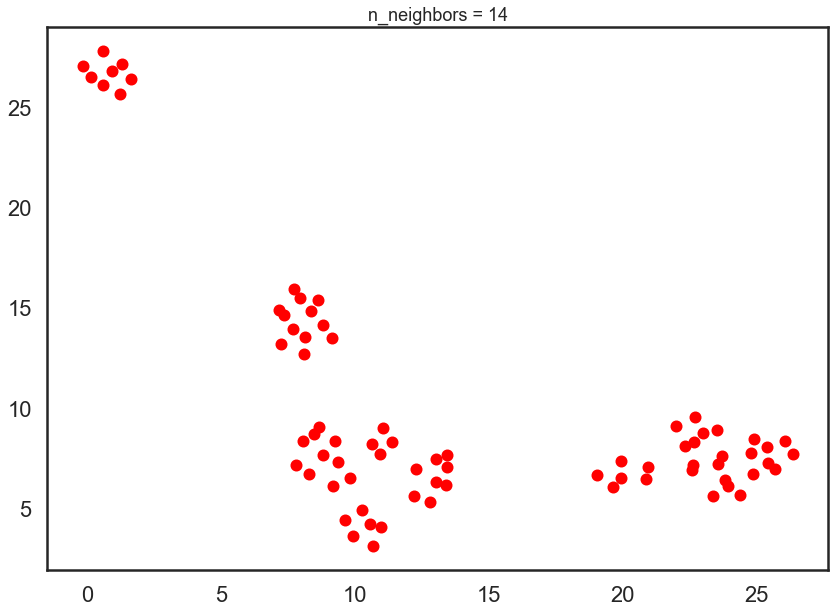

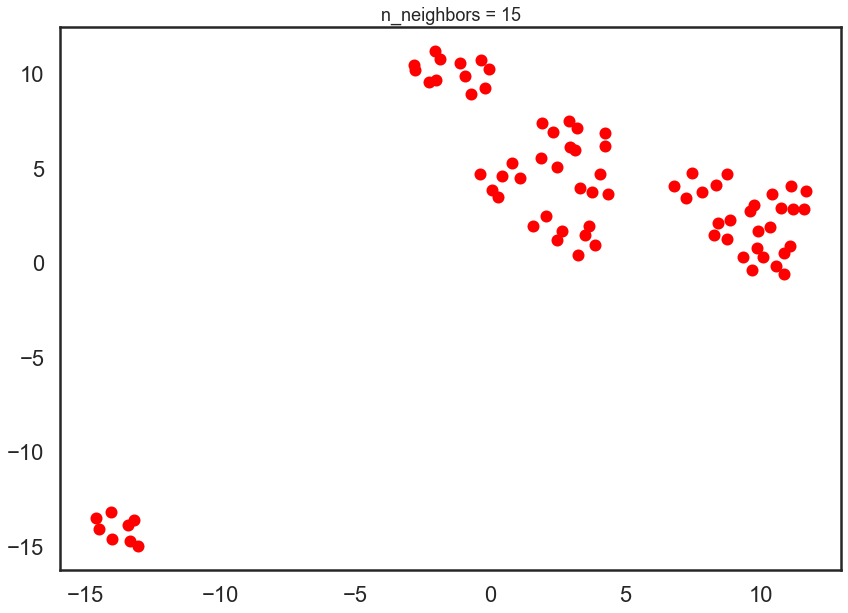

In [23]:
plt.figure(figsize=(8, 4))
for n in (14,15):
    draw_umap(n_neighbors=n, min_dist=0.99, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scaled_features_df_messtage)

## we can see the clusters in the reduced data (3 clusters)

## the parameters need to be tuned

## Testing UMAP with test data 

In [24]:
import statistics

test = pd.read_csv('data/cleaned data/test_data.csv')
## fix classes
test['ID 1'] = test['ID 1'].apply(lambda x: 'St 48' if '48' in x else x)
test['ID 1'] = test['ID 1'].apply(lambda x: 'St 37' if '37' in x else x)

classes = test['ID 1'].unique()
filtered_test = test.drop(['ID 1','Grade'],axis=1)
print('the classes found are : ',classes)
print('Variances : ')
for col in filtered_test.columns:
    print('column ',col, ' with variance : ',statistics.variance(filtered_test[col]))

the classes found are :  ['St 48' 'St 37' 'StSi']
Variances : 
column  Fe  with variance :  0.08525371981095162
column  C  with variance :  0.005898505950688778
column  Si  with variance :  0.03140222432877073
column  Mn  with variance :  0.014014861414553537
column  P  with variance :  0.00012529846728671288
column  S  with variance :  0.00014898209489826758
column  Cr  with variance :  0.00018320636210308755
column  Mo  with variance :  0.0008724694582273114
column  Ni  with variance :  0.0004497132317349595
column  Al  with variance :  5.256671540025153e-05
column  Co  with variance :  4.127953506283335e-06
column  Cu  with variance :  0.0028454239753151413
column  Nb  with variance :  4.787488118218245e-06
column  Ti  with variance :  5.154433915357843e-07
column  V  with variance :  3.070567668879727e-07
column  W  with variance :  6.596082302360269e-07
column  Pb  with variance :  2.0802341259395756e-06
column  Sn  with variance :  8.048472569535843e-05
column  B  with variance :

C:\Users\21260\anaconda3\lib\site-packages\seaborn\distributions.py:305: UserWarning: Dataset has 0 variance; skipping density estimate.
  warnings.warn(msg, UserWarning)


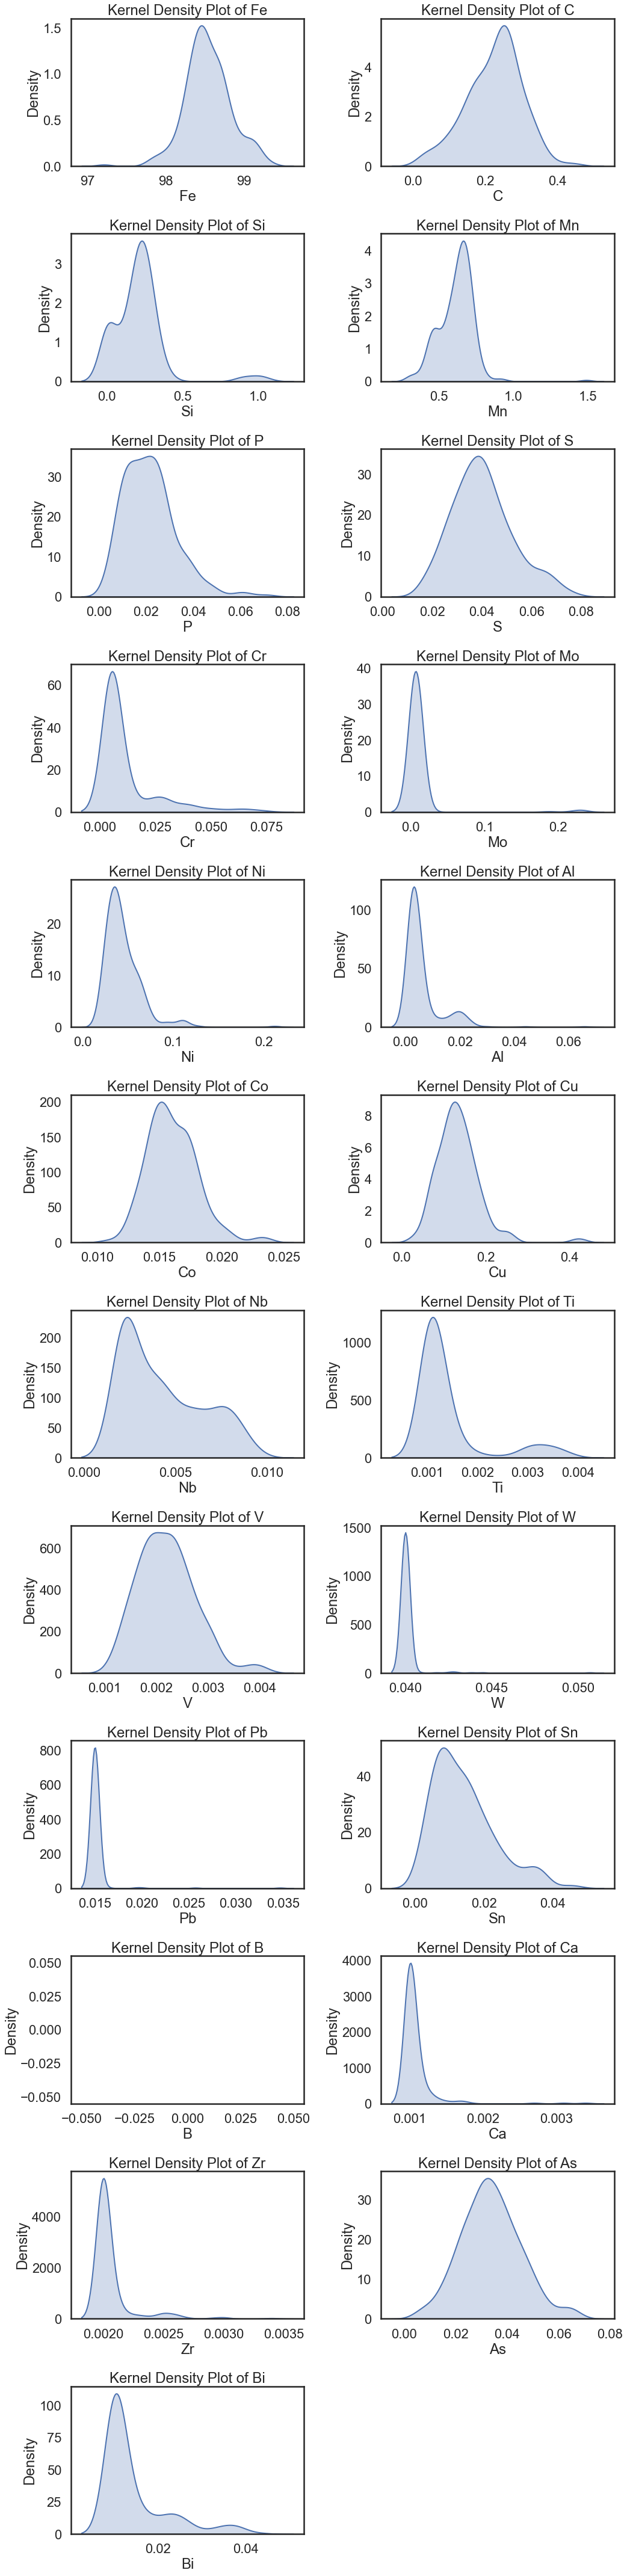

In [25]:
columns = filtered_test.columns
num_columns = len(columns)
num_rows = (num_columns // 2) + (num_columns % 2)
num_cols = 2
plt.figure(figsize=(15, 5 * num_rows))
for i, column in enumerate(columns, 1):
    plt.subplot(num_rows, num_cols, i)  
    sn.kdeplot(filtered_test[column], shade=True,color='b') 
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(f'Kernel Density Plot of {column}')  
plt.tight_layout()
plt.show()

In [26]:
ct = ColumnTransformer([
        ('somename', StandardScaler(), filtered_test.columns)
    ], remainder='passthrough')
scaled_df_test = ct.fit_transform(filtered_test)
scaled_features_df_test = pd.DataFrame(scaled_df_test, index=filtered_test.index, columns=filtered_test.columns)


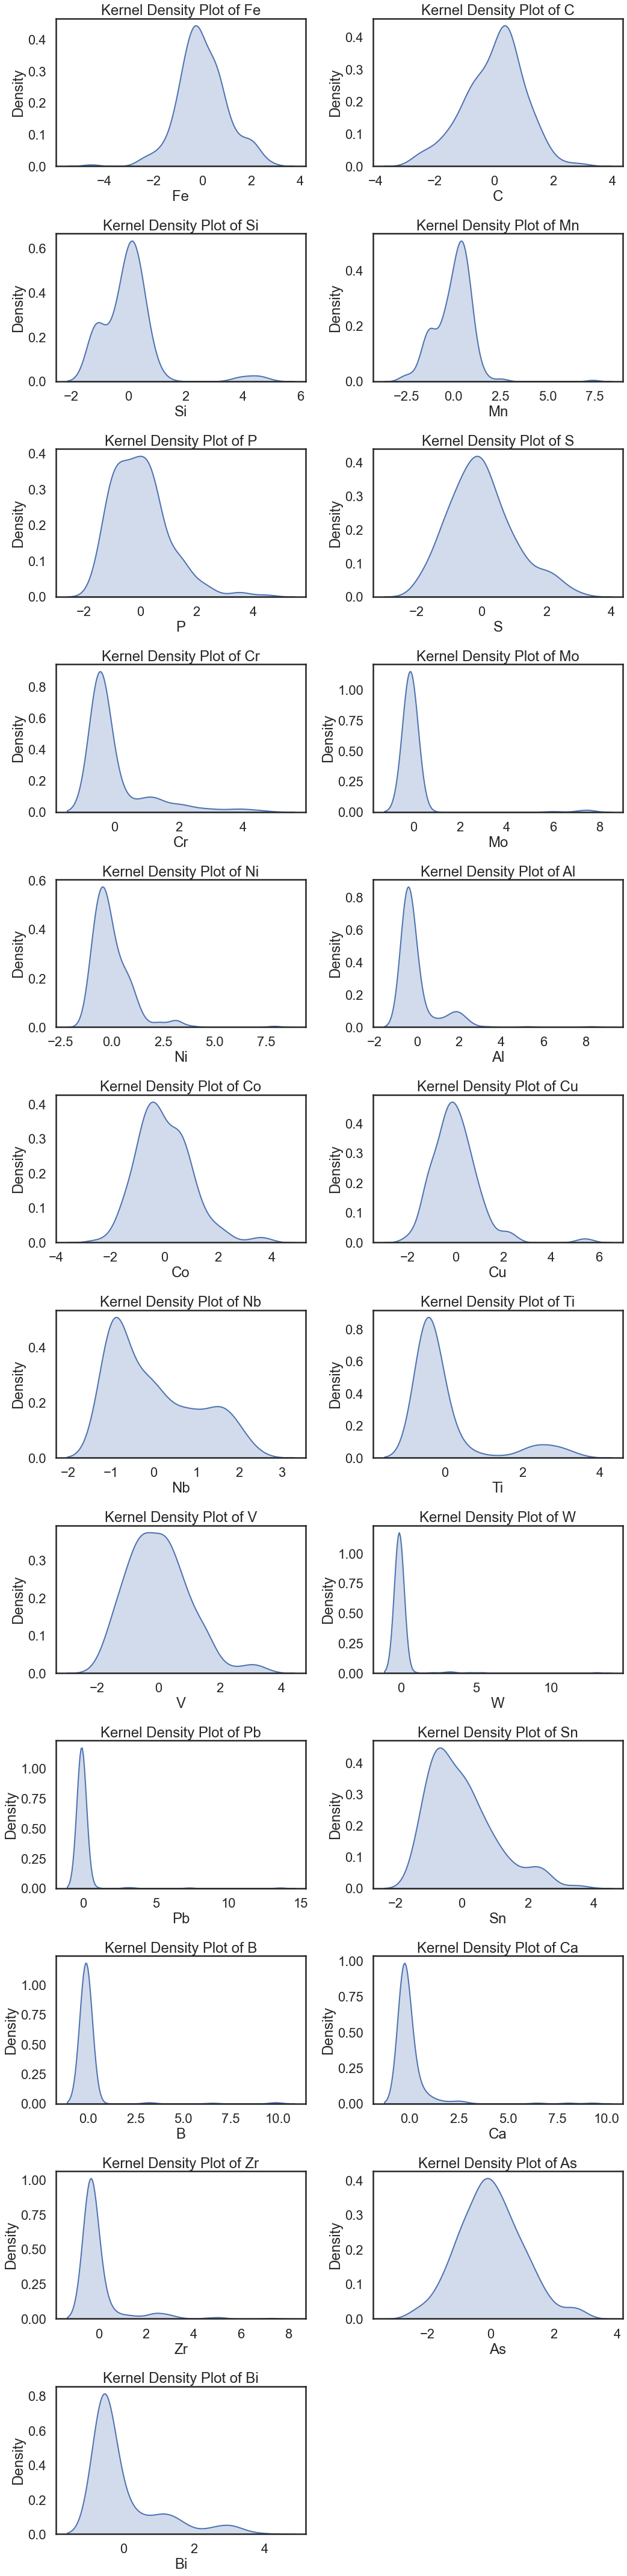

In [27]:
columns = scaled_features_df_test.columns
num_columns = len(columns)
num_rows = (num_columns // 2) + (num_columns % 2)
num_cols = 2
plt.figure(figsize=(15, 5 * num_rows))
for i, column in enumerate(columns, 1):
    plt.subplot(num_rows, num_cols, i)  
    sn.kdeplot(scaled_features_df_test[column], shade=True,color='b') 
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(f'Kernel Density Plot of {column}')

plt.tight_layout()
plt.show()

## testing umap

<Figure size 576x288 with 0 Axes>

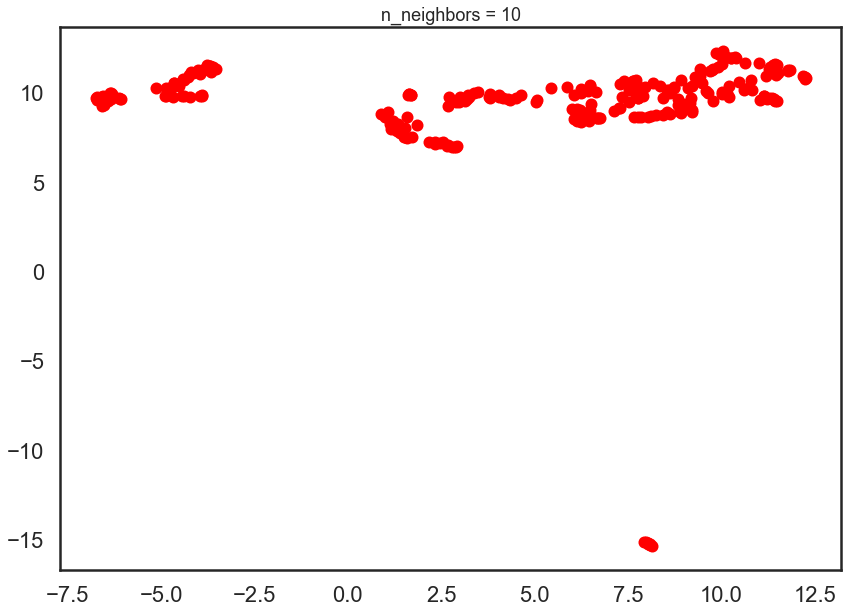

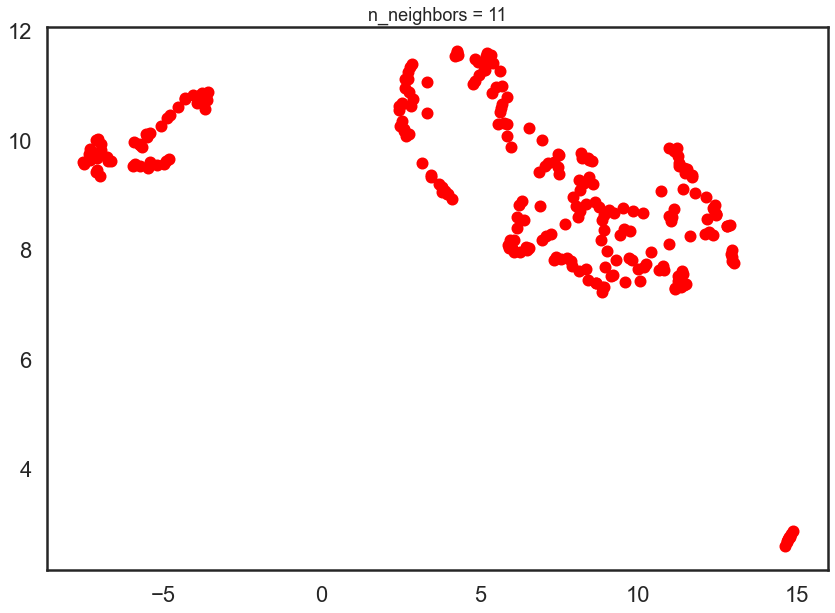

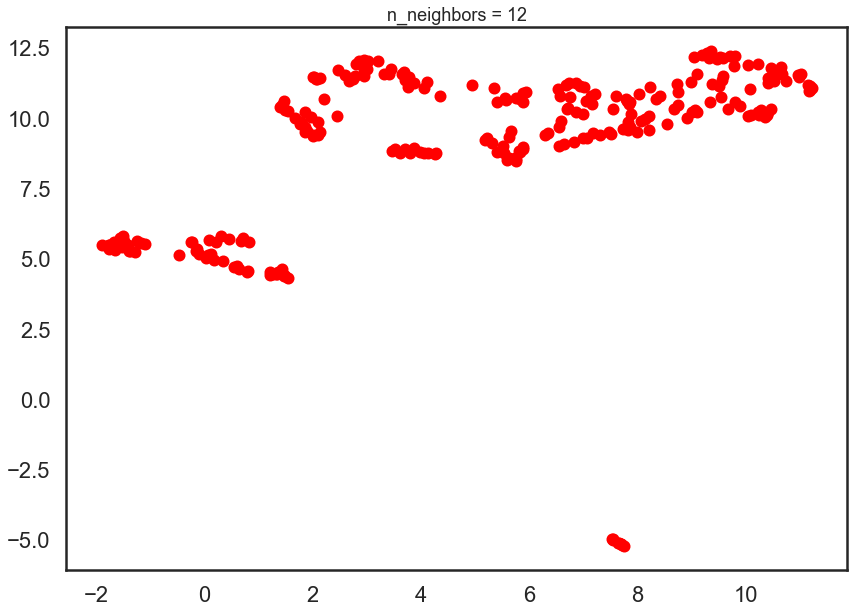

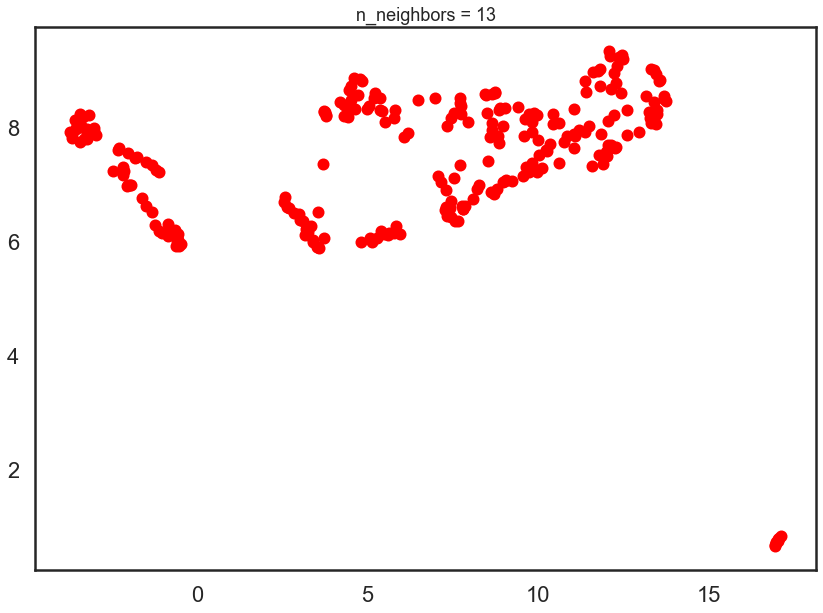

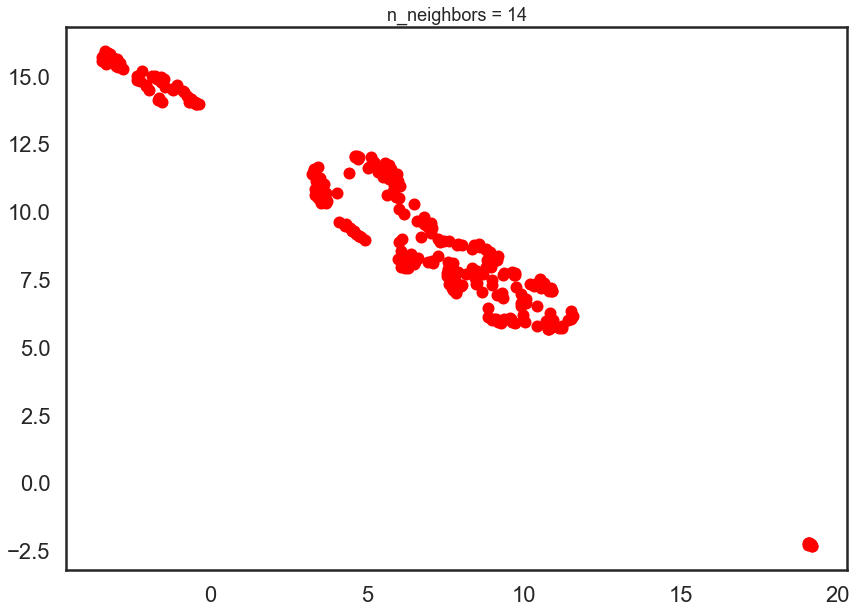

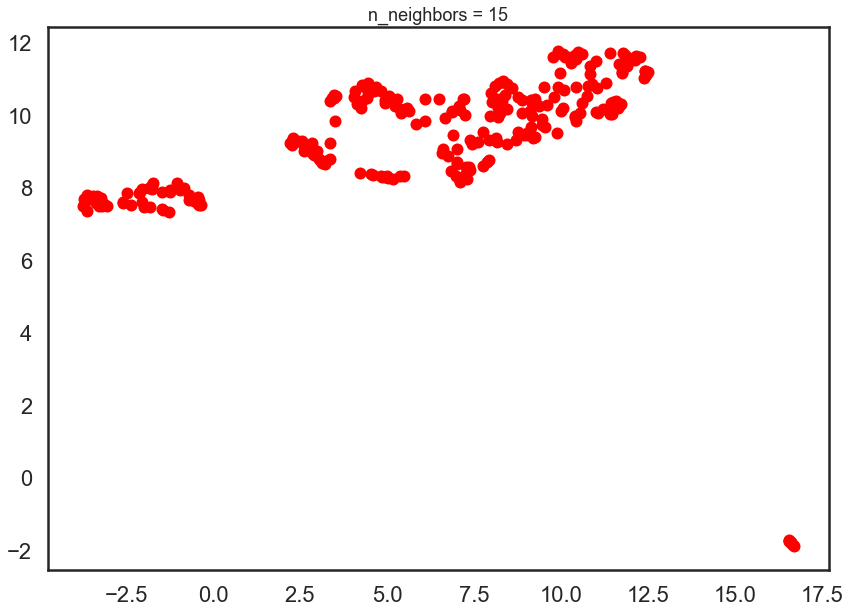

In [28]:
plt.figure(figsize=(8, 4))
for n in (10, 11, 12, 13,14,15):
    draw_umap(n_neighbors=n, min_dist=0.1, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=filtered_test)

## we can see the cluster in the reduced dataset (3 clusters)

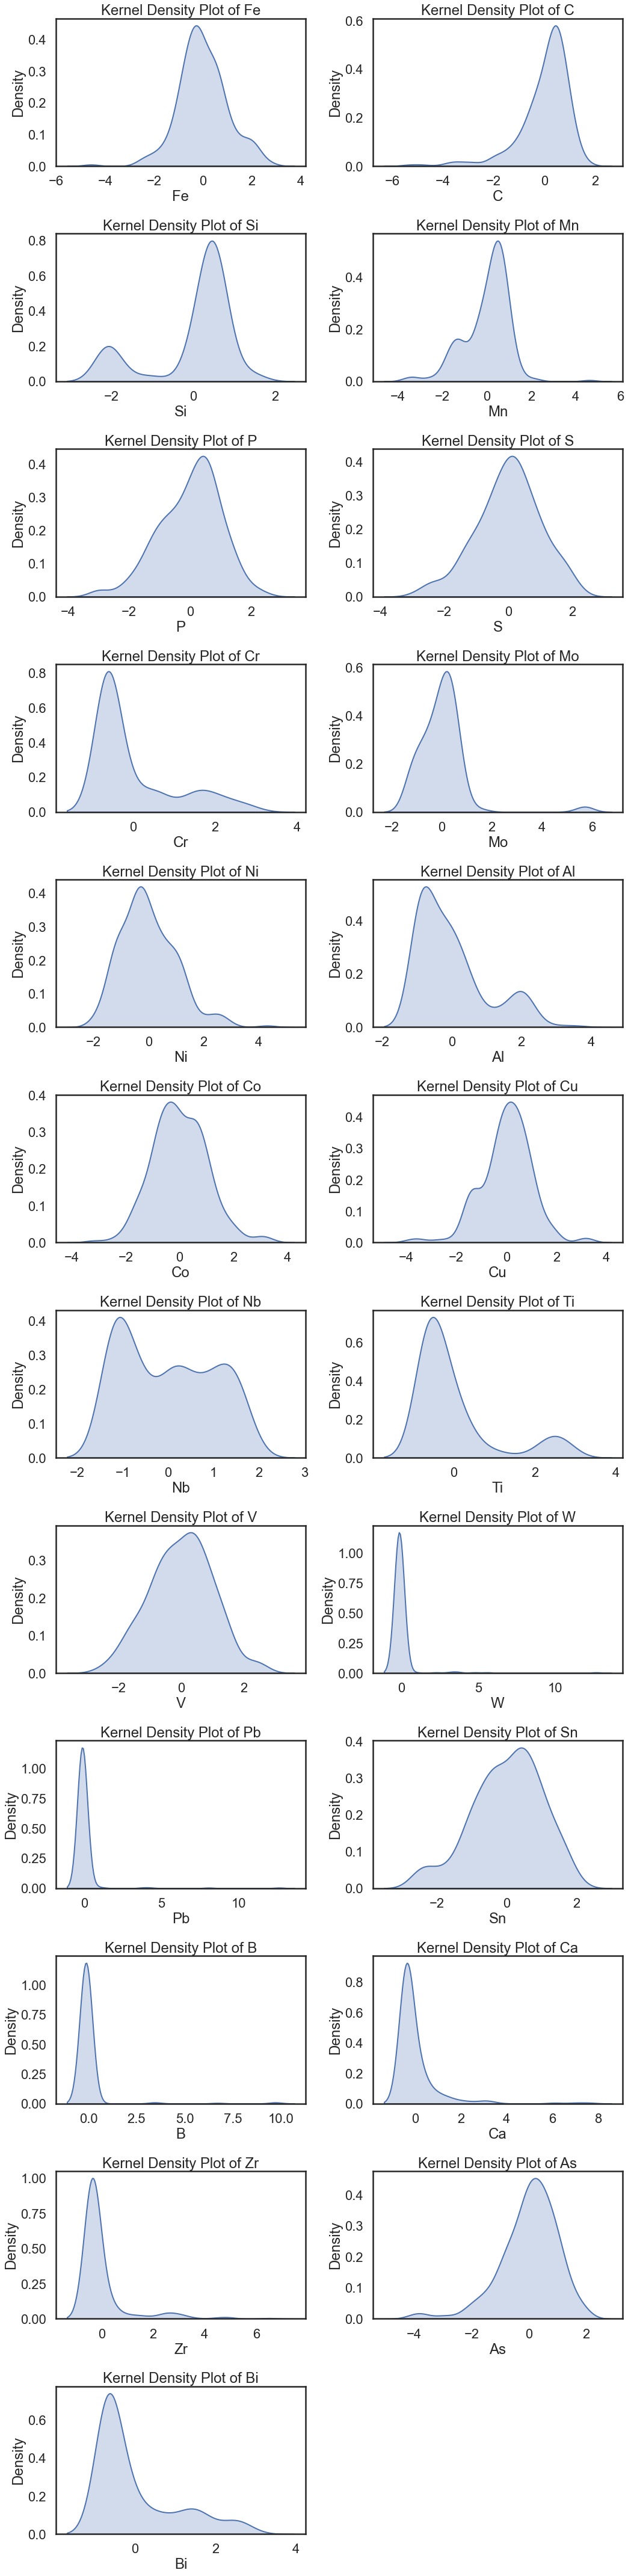

In [29]:
log_test = np.log(filtered_test)
ct = ColumnTransformer([
        ('somename', StandardScaler(), log_test.columns)
    ], remainder='passthrough')
scaled_df_test_log = ct.fit_transform(log_test)
scaled_features_df_test_log = pd.DataFrame(scaled_df_test_log, index=log_test.index, columns=log_test.columns)
columns = scaled_features_df_test_log.columns
num_columns = len(columns)
num_rows = (num_columns // 2) + (num_columns % 2)
num_cols = 2
plt.figure(figsize=(15, 5 * num_rows))
for i, column in enumerate(columns, 1):
    plt.subplot(num_rows, num_cols, i)  
    sn.kdeplot(scaled_features_df_test_log[column], shade=True,color='b') 
    plt.xlabel(column)
    plt.ylabel('Density')
    plt.title(f'Kernel Density Plot of {column}')
plt.tight_layout()
plt.show()

<Figure size 576x288 with 0 Axes>

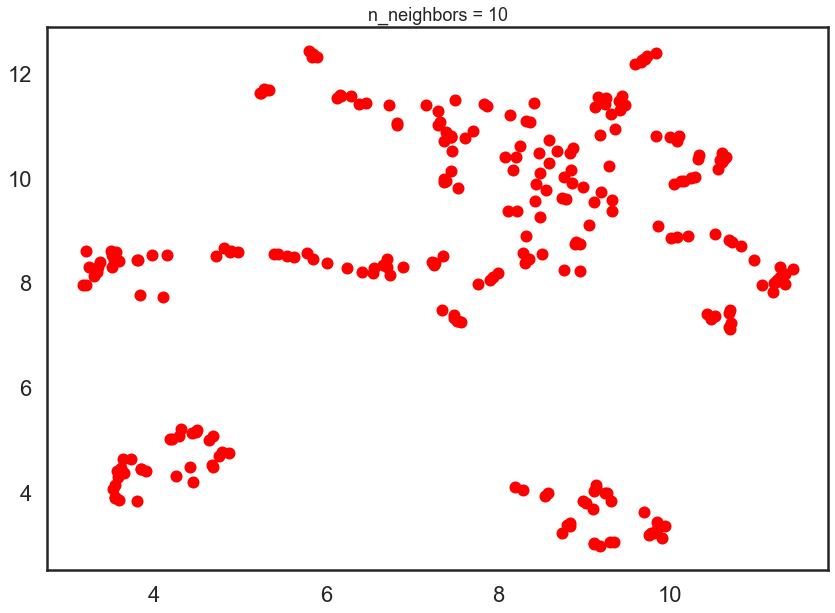

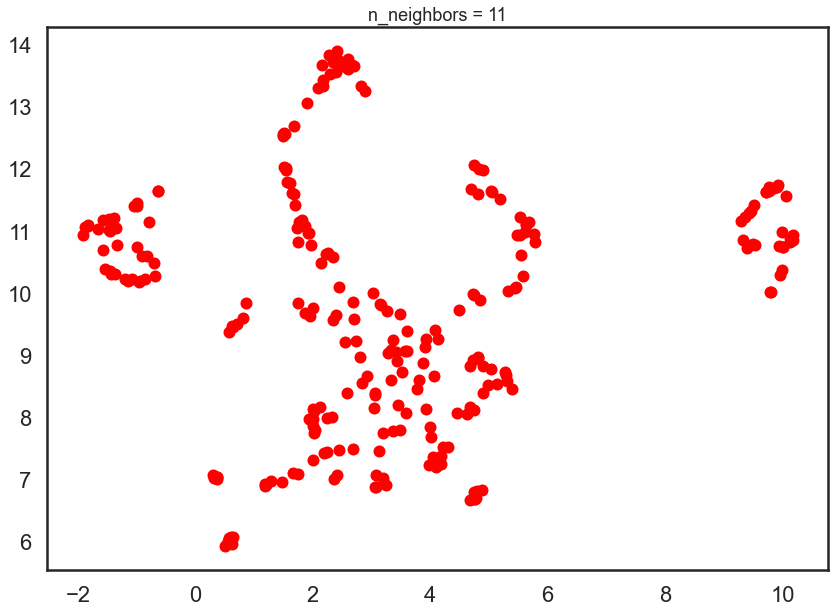

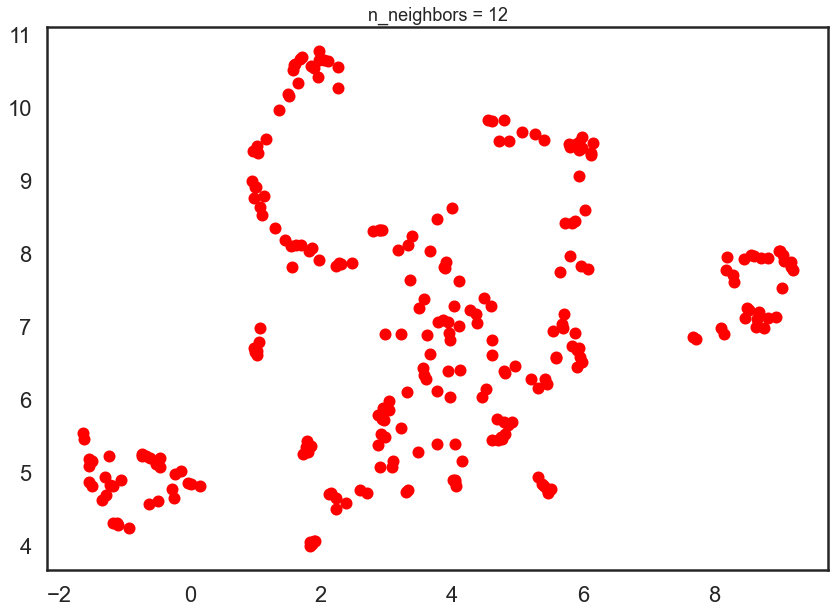

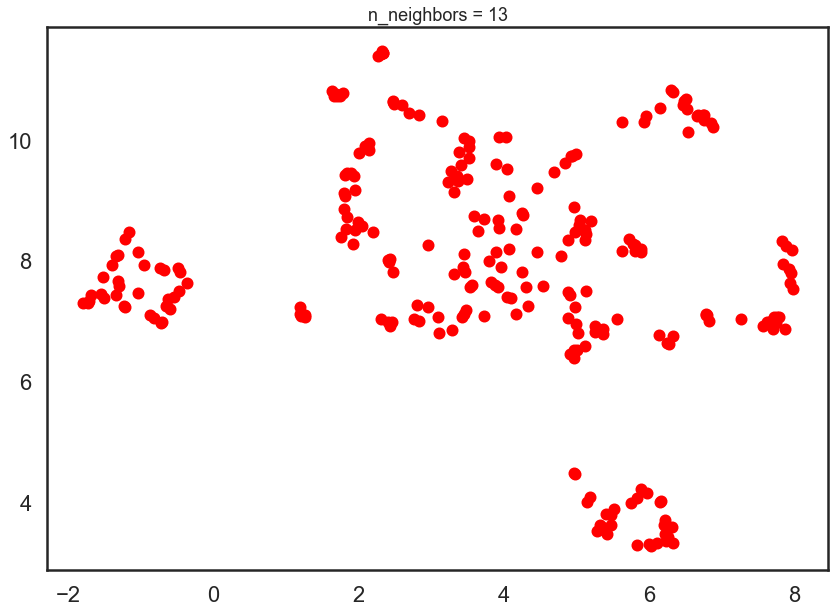

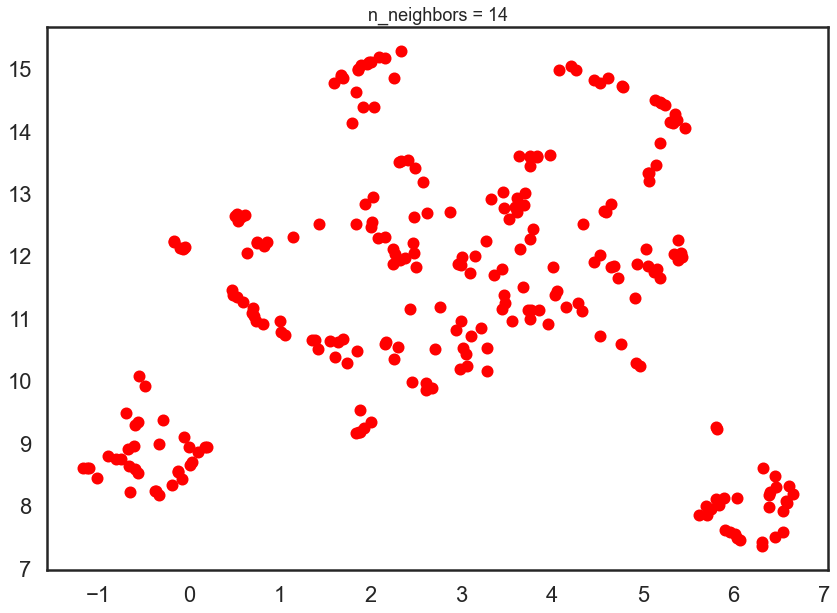

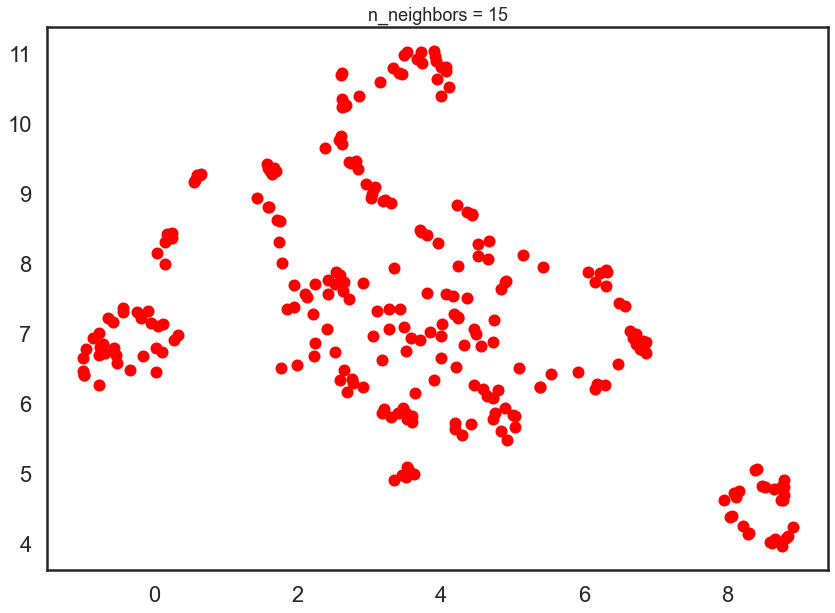

In [30]:
plt.figure(figsize=(8, 4))
for n in (10, 11, 12, 13,14,15):
    draw_umap(n_neighbors=n, min_dist=0.1, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scaled_features_df_test_log)

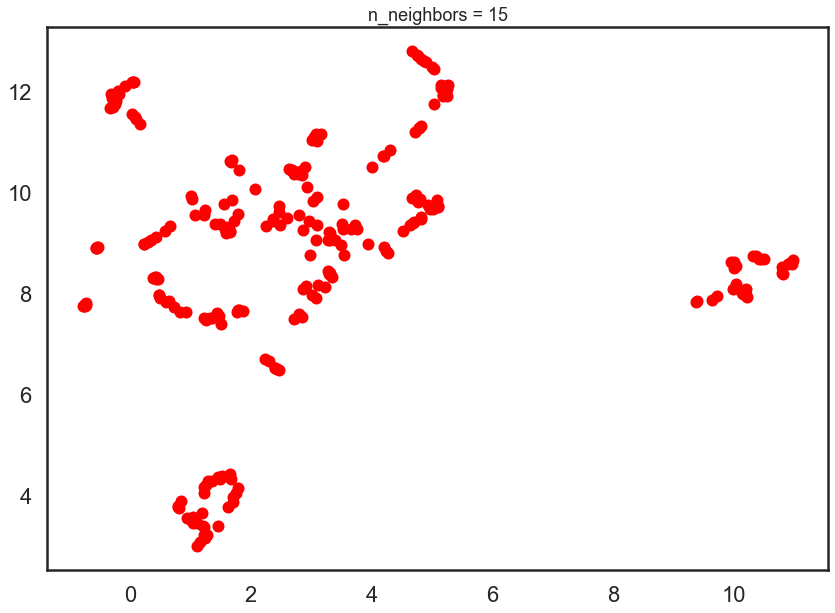

In [31]:
draw_umap(n_neighbors=11, min_dist=0.004, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scaled_features_df_test_log)

## we can see the number of cluster using 15 n_neighbors

## Trying hierarchical (agglomerative) clustering 

In [32]:
test_fit = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric='euclidean'
    )
u_test = test_fit.fit_transform(filtered_test)


In [33]:
from sklearn.cluster import AgglomerativeClustering

def hierarchical(data):
    cluster = AgglomerativeClustering(
    n_clusters=3, metric='euclidean', linkage='ward')
    cluster.fit(data)
    labels = cluster.labels_
    data['labels'] = labels
    return (data,labels)

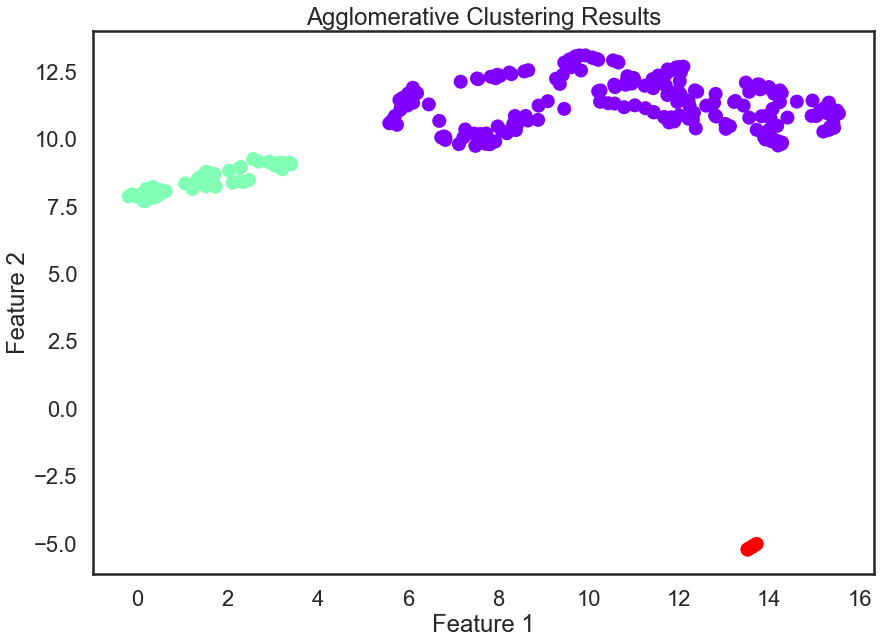

In [34]:
result_df = pd.DataFrame(u_test)
# Plot the clustered results
clustered_df,labels = hierarchical(result_df)
plt.scatter(clustered_df[clustered_df.columns[0]], clustered_df[clustered_df.columns[1]], c=labels, cmap='rainbow')
plt.title('Agglomerative Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

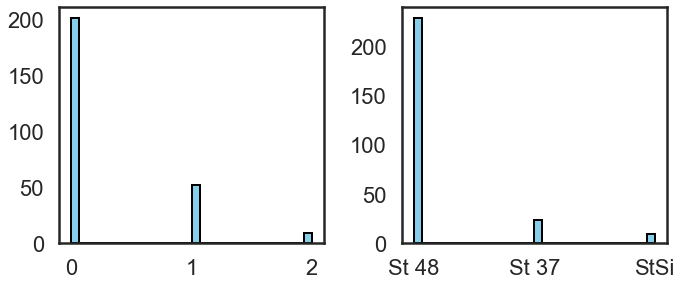

In [35]:
plt.rcParams["figure.figsize"] = [10, 4.50]
plt.rcParams["figure.autolayout"] = True
fig, axes = plt.subplots(1, 2)


axes[0].hist(labels, bins=30, color='skyblue', edgecolor='black')
axes[1].hist(test['ID 1'], bins=30, color='skyblue', edgecolor='black')

plt.show()

# we fed the reduced dataset to the algorithm and the results are pretty good

In [36]:
test_fit = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        metric='euclidean'
    )
u_test = test_fit.fit_transform(log_test)

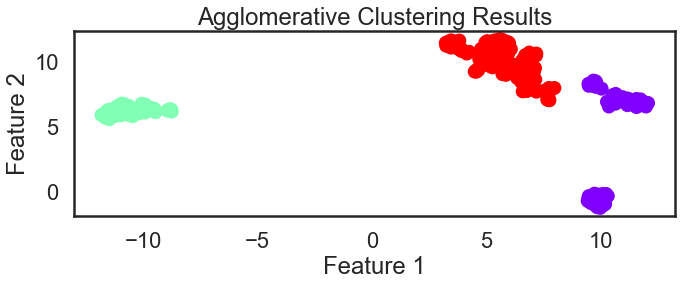

In [37]:
result_df = pd.DataFrame(u_test)
# Plot the clustered results
clustered_df,labels = hierarchical(result_df)
plt.scatter(clustered_df[clustered_df.columns[0]], clustered_df[clustered_df.columns[1]], c=labels, cmap='rainbow')
plt.title('Agglomerative Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()


## we can see the clusters (3 clusters)

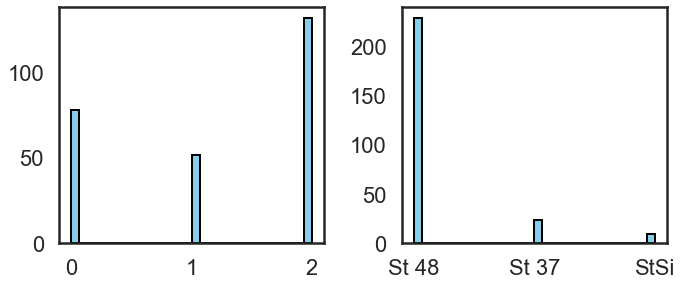

In [38]:
plt.rcParams["figure.figsize"] = [10, 4.50]
plt.rcParams["figure.autolayout"] = True
fig, axes = plt.subplots(1, 2)

# Plotting a histogram to see distribution of clusters
axes[0].hist(labels, bins=30, color='skyblue', edgecolor='black')
axes[1].hist(test['ID 1'], bins=30, color='skyblue', edgecolor='black')
# Display the plot
plt.show()

Silhouette Score: 0.6707870859618229


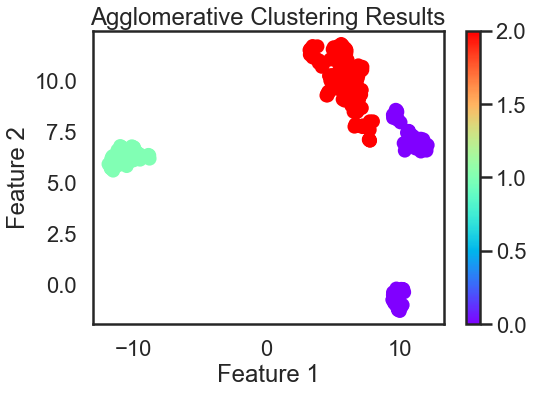

In [39]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import pandas as pd

# Calculate Silhouette Score
silhouette_avg = silhouette_score(result_df, labels)
print(f"Silhouette Score: {silhouette_avg}")

# Visualize Clustered Data Points
plt.figure(figsize=(8, 6))
plt.scatter(clustered_df[clustered_df.columns[0]], clustered_df[clustered_df.columns[1]], c=labels, cmap='rainbow')
plt.title('Agglomerative Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.colorbar()
plt.show()

Silhouette Score for 2 clusters: 0.7647910118103027
Silhouette Score for 3 clusters: 0.6542837023735046
Silhouette Score for 4 clusters: 0.7204672694206238
Silhouette Score for 5 clusters: 0.6537320613861084
Silhouette Score for 6 clusters: 0.6214044094085693


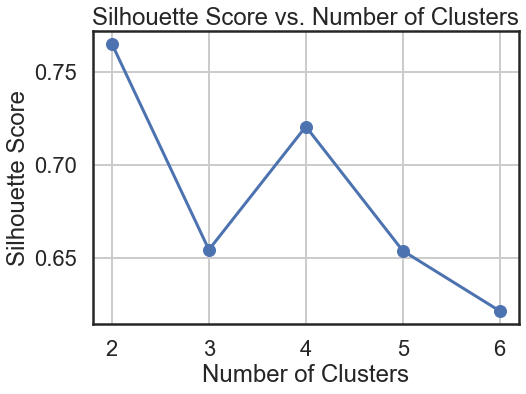

Optimal Number of Clusters: 2


In [40]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import pandas as pd
result_df = pd.DataFrame(u_test)
silhouette_scores = []
cluster_numbers = range(2, 7)  
for n_clusters in cluster_numbers:
    clustering = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
    labels = clustering.fit_predict(result_df)
    silhouette_avg = silhouette_score(result_df, labels)
    silhouette_scores.append(silhouette_avg)
    print(f"Silhouette Score for {n_clusters} clusters: {silhouette_avg}")
plt.figure(figsize=(8, 6))
plt.plot(cluster_numbers, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.grid(True)
plt.show()
optimal_cluster_number = cluster_numbers[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal Number of Clusters: {optimal_cluster_number}")

## the optimal number of clusters we got is the same as the number of cluster in the dataset

## the umap algorithm is a probabilistic approach, so everytime we get a new result

## now using the original datasets without reduction

In [41]:
ct1 = ColumnTransformer([
        ('somename', StandardScaler(), df1.columns)
    ], remainder='passthrough')
scFiltered1 = ct1.fit_transform(df1)
scfFiltered1 = pd.DataFrame(scFiltered1, index=df1.index, columns=df1.columns)


ct2 = ColumnTransformer([
        ('somename', StandardScaler(), df2.columns)
    ], remainder='passthrough')
scFiltered2 = ct2.fit_transform(df2)
scfFiltered2 = pd.DataFrame(scFiltered2, index=df2.index, columns=df2.columns)


ct3 = ColumnTransformer([
        ('somename', StandardScaler(), df3.columns)
    ], remainder='passthrough')
scFiltered3 = ct3.fit_transform(df3)
scfFiltered3 = pd.DataFrame(scFiltered3, index=df3.index, columns=df3.columns)

In [42]:
## define agglomerative function
def hierarchical(data,c):
    cluster = AgglomerativeClustering(
    n_clusters=c, metric='euclidean', linkage='ward')
    cluster.fit(data)
    labels = cluster.labels_
    data['labels'] = labels
    return (data,labels)

In [43]:
# Calculate Silhouette Score
scfFiltered1 = pd.DataFrame(scfFiltered1)
scfFiltered2 = pd.DataFrame(scfFiltered2)
scfFiltered3 = pd.DataFrame(scfFiltered3)


In [44]:
(clustered_df1,labels1) = hierarchical(scfFiltered1,3)
silhouette_avg1 = silhouette_score(scfFiltered1, labels1)
print(f"Silhouette Score: {silhouette_avg1}")

(clustered_df2,labels2) = hierarchical(scfFiltered2,3)
silhouette_avg2 = silhouette_score(scfFiltered2, labels2)
print(f"Silhouette Score: {silhouette_avg2}")

(clustered_df3,labels3) = hierarchical(scfFiltered3,3)
silhouette_avg3 = silhouette_score(scfFiltered3, labels3)
print(f"Silhouette Score: {silhouette_avg3}")


Silhouette Score: 0.48485775321499
Silhouette Score: 0.3706401594288974
Silhouette Score: 0.2661560873590115


# trying range of n_clusters

In [45]:
for c in (2,3,4,5,6,7,8,9,10):
    (clustered_df1,labels1) = hierarchical(scfFiltered1,c)
    silhouette_avg1 = silhouette_score(scfFiltered1, labels1)
    print(f"Silhouette Score: {silhouette_avg1}")

Silhouette Score: 0.6926361329871772
Silhouette Score: 0.48485775321499
Silhouette Score: 0.20574438332692355
Silhouette Score: 0.2081253706494738
Silhouette Score: 0.2811591500687901
Silhouette Score: 0.33146484244432656
Silhouette Score: 0.23723894107307478
Silhouette Score: 0.29682785236669906
Silhouette Score: 0.2684113271363119


# appears that 2 is the best number of clusters to be found

In [46]:
for c in (15,20,25,30,35):
    (clustered_df2,labels2) = hierarchical(scfFiltered2,c)
    silhouette_avg2 = silhouette_score(scfFiltered2, labels2)
    print(f"Silhouette Score: {silhouette_avg2}")

Silhouette Score: 0.5530035963932267
Silhouette Score: 0.5990226397753606
Silhouette Score: 0.5760782390856087
Silhouette Score: 0.6181298769610651
Silhouette Score: 0.5391675403825207


# not really that clear. too many cluster

In [47]:
for c in (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17):
    (clustered_df3,labels3) = hierarchical(scfFiltered3,c)
    silhouette_avg3 = silhouette_score(scfFiltered3, labels3)
    print(f"Silhouette Score: {silhouette_avg3}")

Silhouette Score: 0.37650866352948803
Silhouette Score: 0.2661560873590115
Silhouette Score: 0.3138887635836421
Silhouette Score: 0.4065342065876846
Silhouette Score: 0.3951517629590975
Silhouette Score: 0.4283061799988685
Silhouette Score: 0.46059563154166233
Silhouette Score: 0.46519719322369096
Silhouette Score: 0.5309764997878691
Silhouette Score: 0.5330254002919665
Silhouette Score: 0.5701251652820797
Silhouette Score: 0.6713146421354814
Silhouette Score: 0.675560399450885
Silhouette Score: 0.6618942435055823
Silhouette Score: 0.7179817433833009
Silhouette Score: 0.6867082134516437


# with this dataset as well

<Figure size 576x288 with 0 Axes>

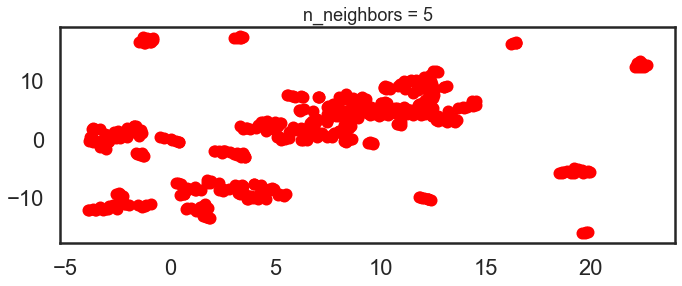

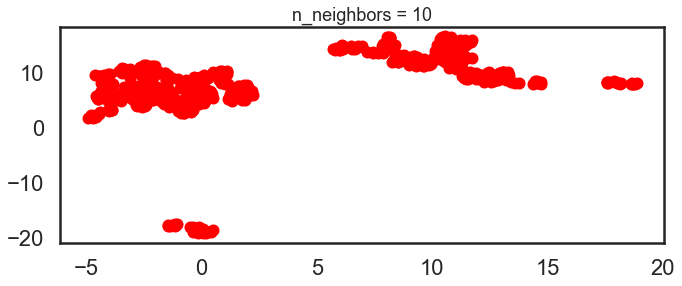

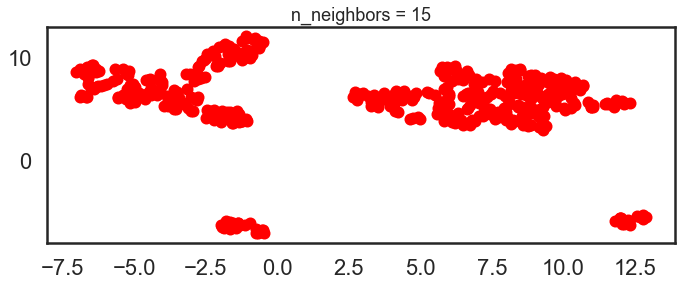

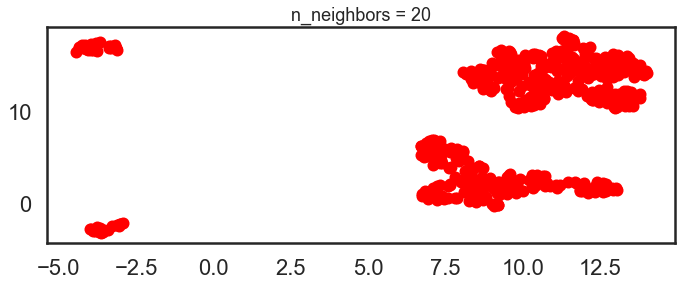

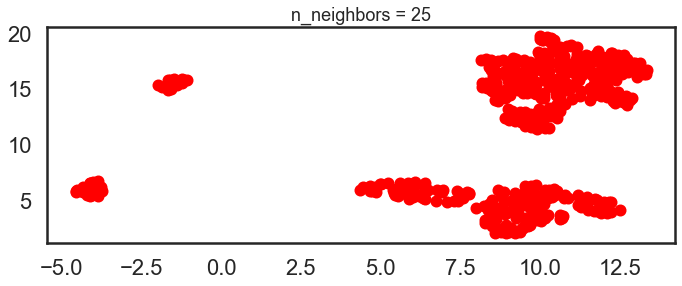

In [48]:
### reducing and visualisation
plt.figure(figsize=(8, 4))
for n in (5,10,15,20,25):
    draw_umap(n_neighbors=n, min_dist=0.5, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scfFiltered1)

<Figure size 576x288 with 0 Axes>

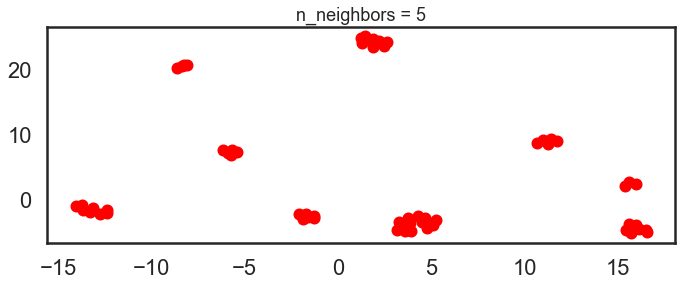

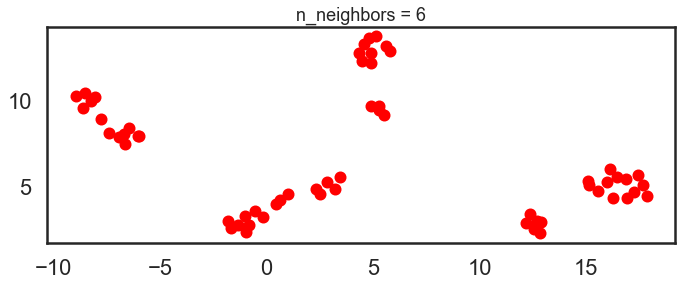

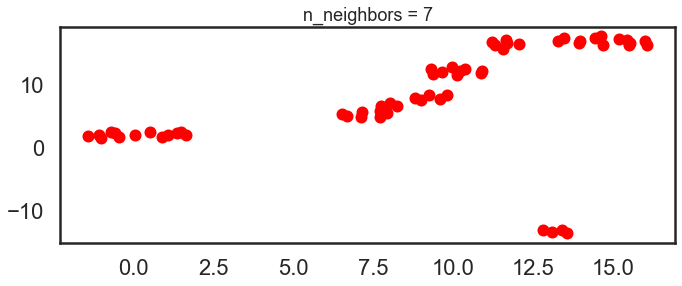

In [49]:
### reducing and visualisation
plt.figure(figsize=(8, 4))
for n in (5,6,7):
    draw_umap(n_neighbors=n, min_dist=0.5, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scfFiltered2)

C:\Users\21260\anaconda3\lib\site-packages\umap\spectral.py:550: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


<Figure size 576x288 with 0 Axes>

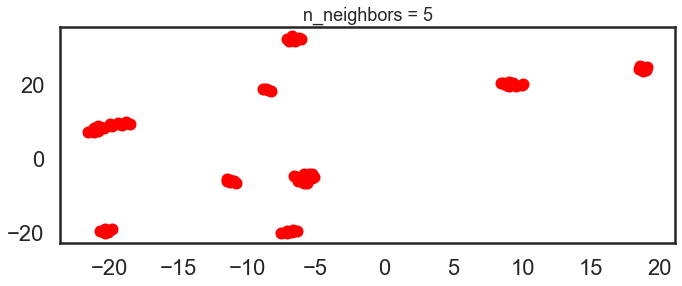

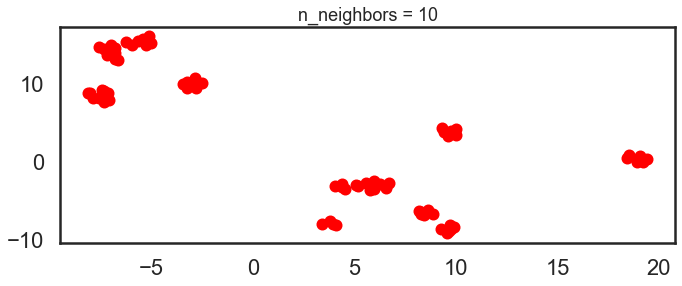

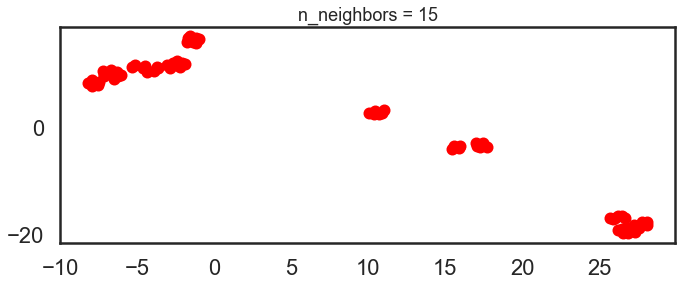

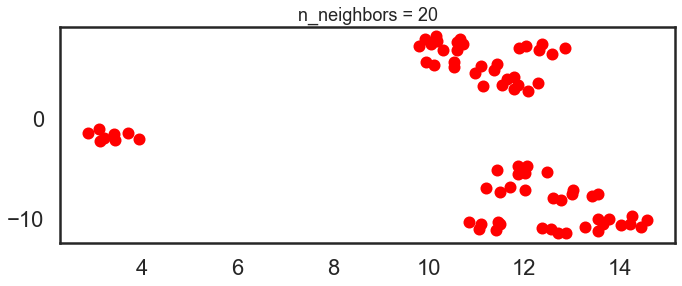

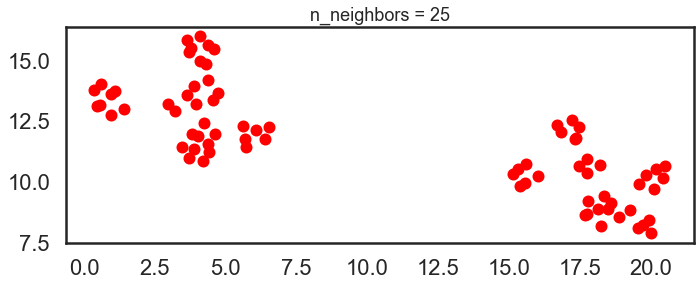

In [50]:
### reducing and visualisation
plt.figure(figsize=(8, 4))
for n in (5,10,15,20,25):
    draw_umap(n_neighbors=n, min_dist=0.5, metric='euclidean', title='n_neighbors = {}'.format(n),
              data=scfFiltered3)

## we will try to do a way of parameter tuning for the umap algorithm. Based on one of the writers of this module we will implement a function that gives the best clustering at the end. It means we will cluster data first, get the best number of clusters using silhouette score. After that we will try to reduce the dataset with umap, cluster and calculate the silhouette score again and it should be the as high as the original dataset.

In [51]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV


param_grid = {"n_clusters": range(2, 18)}


def silhouette_scorer(estimator, X):
    clusters = estimator.fit_predict(X)
    score = silhouette_score(X, clusters)
    return score


model = AgglomerativeClustering()
grid_search = GridSearchCV(model, param_grid=param_grid, scoring=silhouette_scorer)
grid_search.fit(scaled_features_df_test)
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("Best number of clusters:", best_params['n_clusters'])
print("Best silhouette score:", best_score)

Best number of clusters: 2
Best silhouette score: 0.4191572186150501


## we implemented a grid search to find the best cluster number

In [55]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from umap import UMAP

range_neighbors = [5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]
range_mindist = [0.1, 0.2, 0.3, 0.4, 0.5,0.8,0.9]



def recommend_pars(data, range_neighbors, range_mindist):
    best_model = None
    best_score = -1
    for i in range_neighbors:
        for j in range_mindist:
            pipeline = Pipeline([
                ('umap', UMAP(n_neighbors=i,
                              min_dist=j,
                              n_components=2,
                              metric='euclidean')),
                ('clustering', AgglomerativeClustering(n_clusters=3))
            ])
            cluster_labels = pipeline.fit_predict(data)
            silhouette_score_pipeline = silhouette_score(data, cluster_labels)
            print(silhouette_score_pipeline)
            if silhouette_score_pipeline > best_score:
                best_score = silhouette_score_pipeline
                best_model = pipeline

    return best_model,best_score

best_model,best_score = recommend_pars(scaled_features_df_test, range_neighbors, range_mindist)

print("Best silhouette score:", best_score)

0.06655635248491712
0.09596607459787213
0.07692757541115984
0.07056163641749151
0.05287296006756416
0.06530535521265605
0.052586535000568105
0.05869153807844352
0.056463066925841666
0.05869153807844352
0.10139903552436672
0.05361250133783857
0.08572751213196088
0.08335840083315986
0.093130400932713
0.0908688007679528
0.07856525010549144
0.07290921125990946
0.04580572716680931
0.06183154528284089
0.09367422786439127
0.056463066925841666
0.09605238070751672
0.10916065347125194
0.08860481355608149
0.08276806288402805
0.0852644935093658
0.09906618086398546
0.10891123586925963
0.10204046797823213
0.0955175836027489
0.1032539795653197
0.0990916089056892
0.08793478991819098
0.08756422973988648
0.11119249358368281
0.11119249358368281
0.10697815845260751
0.0863034850865828
0.09627415408060075
0.08824533413068664
0.09583755045342135
0.11290453592693252
0.11002748989460222
0.12021861528067002
0.10312874249531777
0.0908688007679528
0.0852194038943324
0.09127129282231272
0.11119249358368281
0.09760

In [53]:
logged_filtered_test = np.log(filtered_test)
ct_log = ColumnTransformer([
        ('somename', StandardScaler(), logged_filtered_test.columns)
    ], remainder='passthrough')
scaled_df_test_loged = ct.fit_transform(logged_filtered_test)
#scaled_features_df_test_loged = pd.DataFrame(scaled_df_test_loged, index = scaled_df_test_loged.index, columns = scaled_df_test_loged.columns)

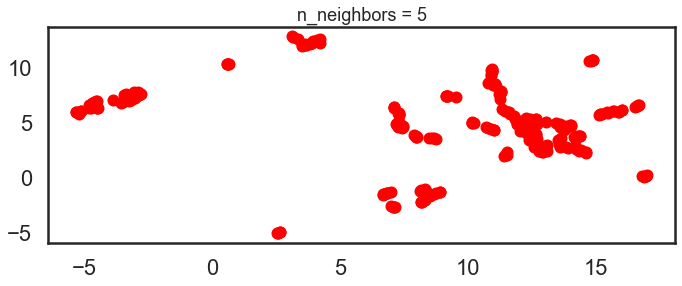

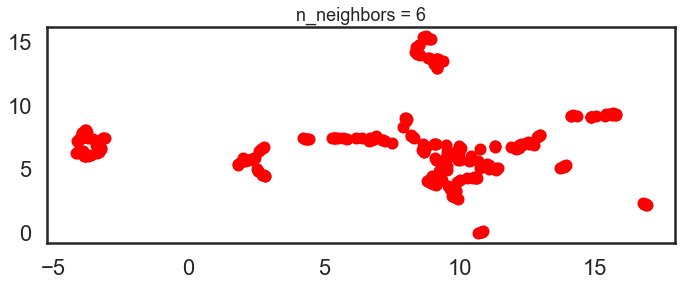

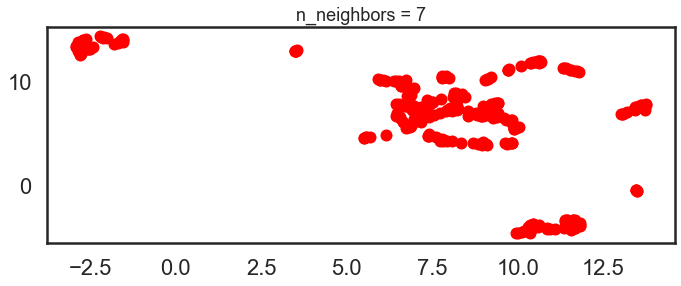

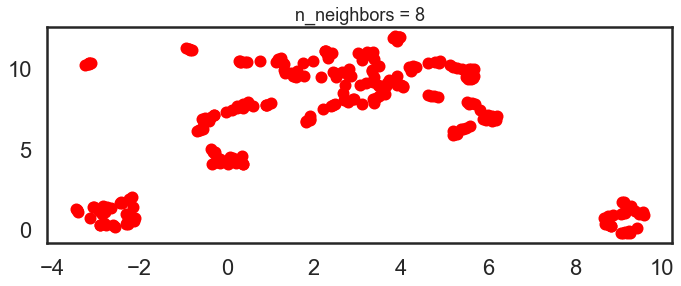

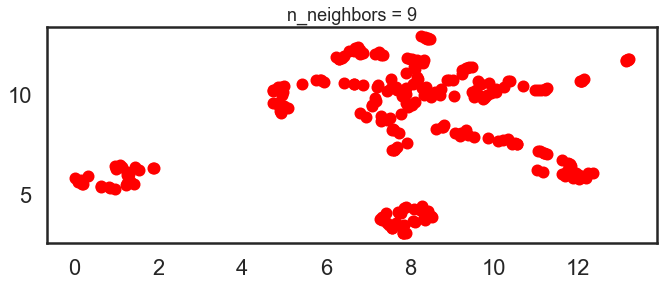

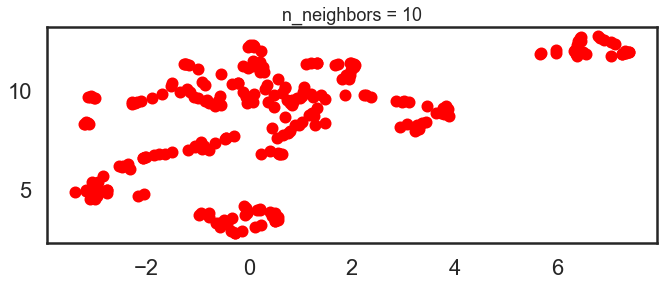

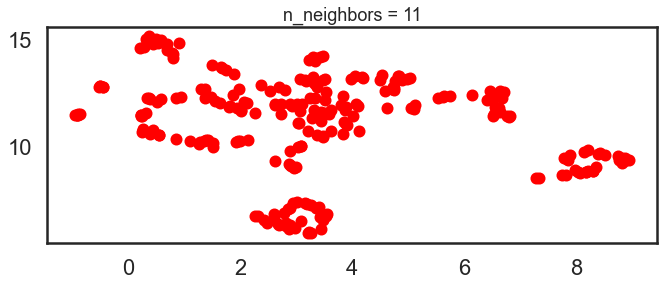

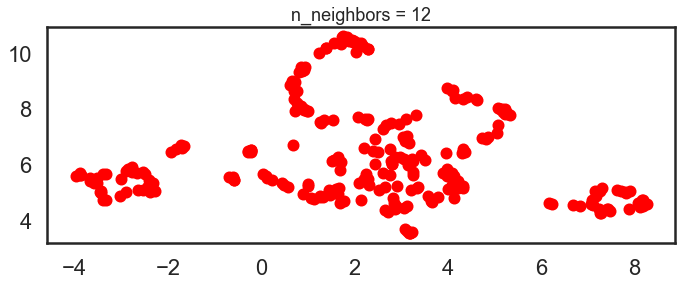

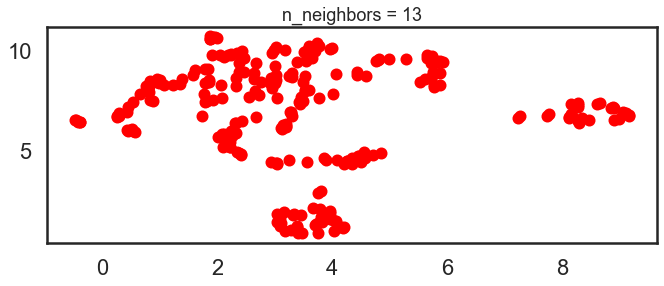

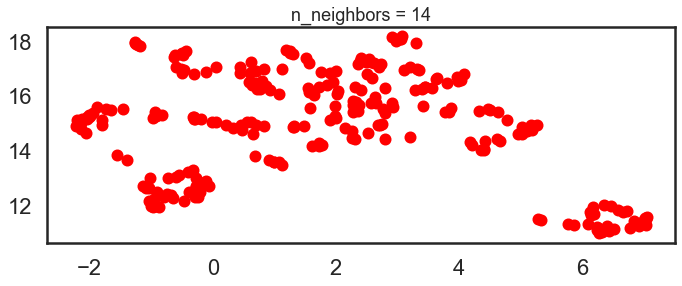

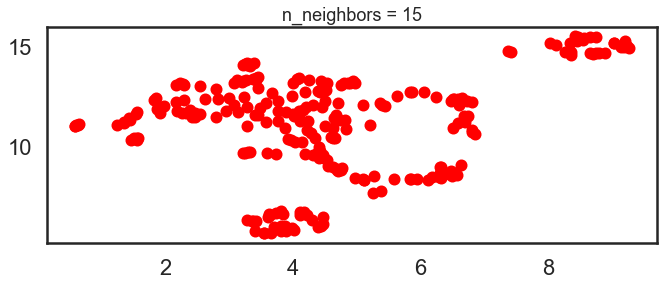

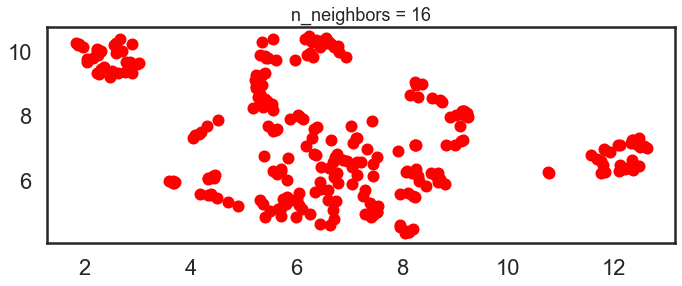

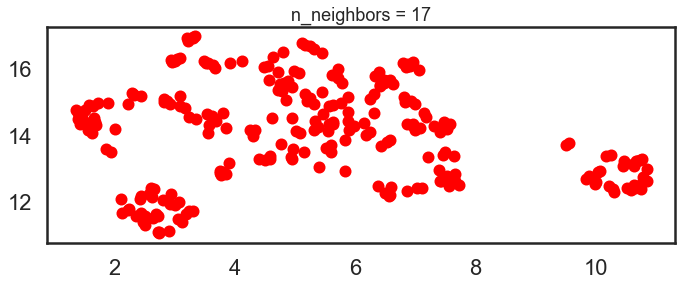

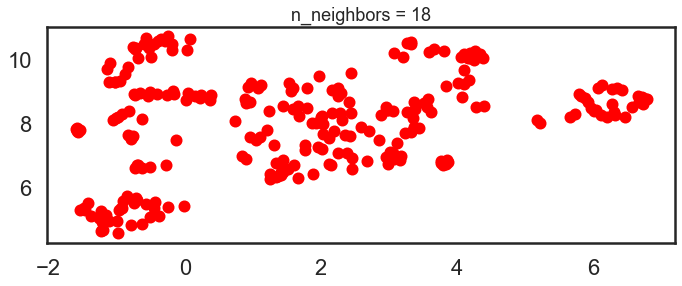

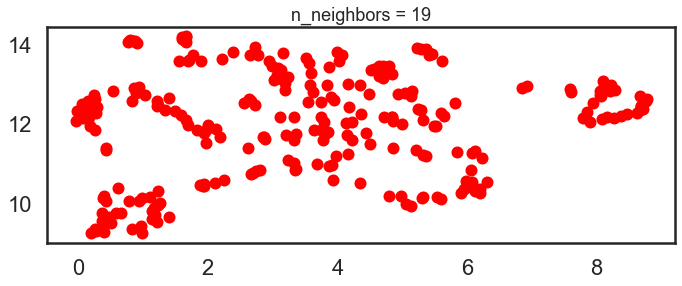

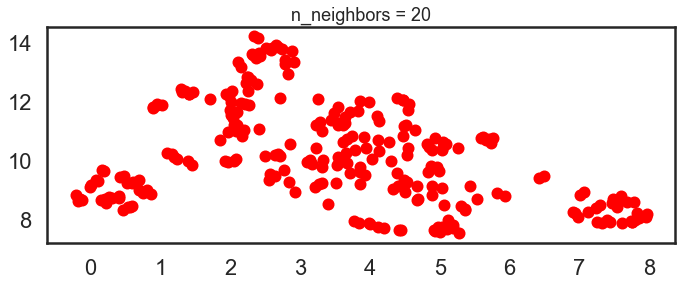

In [54]:
for n in (5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20):
    draw_umap(n_neighbors = n, min_dist = 0.1, metric = 'euclidean', title = 'n_neighbors = {}'.format(n), data = scaled_df_test_loged)

## its easy to see the clusters but the algorithm will find problems clustering because of the small distance between the clusters after reduction 